# Robot interactions across eight recordings

**Does a neighbor change a round robot pair’s outgoing normal or sideways velocity beyond what their own recent motion predicts?** This notebook evaluates the first inward crossing of 1.10 body diameters at 40, 80 and 400 ms. The primary model learns each robot’s free motion on isolated intervals. A subsequent sensitivity run fixes free motion to recent measured velocity. Both use the same encounter definitions, EPDE operators, validation rules and baselines.

The primary model failed the bidirectional transfer test at every horizon. With fixed recent velocity, normal motion at 40 and 80 ms and sideways motion at all three horizons improved on the strongest reference in both directions. Normal motion at 400 ms remains unresolved. The fixed-baseline analysis was motivated by the lack of isolated windows in four dense recordings. The eight recordings have already informed this comparison, so a new recording would provide an independent confirmation.

[Per-fold fronts](results/shared_interaction/all_fronts.csv) · [Fixed-baseline fronts](results/shared_interaction/fixed_drive_fronts.csv) · [Origin and isolation counts](results/shared_interaction/coverage.csv)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

for parent in (Path.cwd(), *Path.cwd().parents):
    options = [parent / "results/shared_interaction", parent / "projects/robot/results/shared_interaction"]
    result = next((p for p in options if (p / "scores.csv").exists()), None)
    if result is not None:
        break
else:
    raise FileNotFoundError("Open this notebook inside the EPDE checkout.")

def read(name):
    return pd.read_csv(result / (name + ".csv"))

scores = read("scores").query("cohort == 'near'").copy()
fixed = read("fixed_drive_scores")
coverage = read("coverage").query("mode == 'native' and kind == 'near'")
display(coverage.groupby("recording")[["crossings","complete","quality_ok","interior","approaching","free_windows"]].sum())
print("Every horizon uses the same", f"{coverage.interior.sum():,}", "gate crossings.")
print("The approaching column counts crossings with positive closing speed measured before the gate.")

,crossings,complete,quality_ok,interior,approaching,free_windows
recording,,,,,,
Experiment_1,10577,10481,10481,7781,7656,13940
Experiment_2,10823,10726,10724,7938,7817,10090
Experiment_3,11238,11128,11126,8542,8401,12510
N30_PWM10_D41,4985,4977,4873,3742,3675,107
N40_PWM10_D40,5515,5505,5209,3282,3215,0
N40_PWM10_D41,6138,6129,5861,3806,3752,0
N40_PWM20_D40,7964,7947,7600,5385,5267,0
N40_PWM20_D41,9299,9281,9008,5991,5871,0


Every horizon uses the same 46,467 gate crossings.
The approaching column counts crossings with positive closing speed measured before the gate.


## Measurements and controls

A new episode requires prior separation of at least $1.30D$, with $D=48.7$ mm. Coordinates below use diameters and seconds. For positions $\mathbf x_i,\mathbf x_j$, set $\mathbf r=\mathbf x_j-\mathbf x_i$, $\mathbf n=\mathbf r(t)/\lVert\mathbf r(t)\rVert$, and $\boldsymbol\tau=(-n_y,n_x)$. For $\mathbf a=\mathbf n,\boldsymbol\tau$, the outcome is
$$u_a(h)=\mathbf a\cdot[\mathbf r(t+h)-\mathbf r(t)]/h.$$
Positive normal motion indicates separation along the original axis. Re-entry, sustained contact and subsequent separation are all eligible. Relative translation of the camera cancels in $\mathbf r$. Rotation, scale change, timing, and marker eccentricity can still affect the target.

Interior crossings require both robots outside the wall band of $0.25D$ from the calibrated center envelope at the gate, complete 440 ms history and 400 ms follow-up, and valid tracks over the interval. The five swarm recordings use the fixed calibrated diameter in pixels. The sweeps use their archived arena-envelope calibrations. Each ZIP is one recording across all its occupancy stages. A separate control uses the $1.70D$ crossing after $1.90D$ clearance, matched without reuse within recording, occupancy and spin class, with maximum closing and sliding speed differences of 0.15 and 0.20 diameters/s.

[Event extraction](collision/shared_interaction_data.py) · [Optical audit](results/shared_interaction/optical_audit.csv) · [Matched distant controls](results/shared_interaction/matched_distant.parquet)

## Free motion and irregular drift

For the free-motion fit, every frame from $t-0.44$ to $t+0.40$ s must be clear of walls and neighbors within $1.5D$. Unknown robot positions invalidate isolation. Define $\mathbf V_{a,b}=[\mathbf x(t-a)-\mathbf x(t-b)]/(b-a)$ and $\omega=[\phi(t-0.04)-\phi(t-0.20)]/0.16$. The five vector predictors are

$$\mathbf V=\mathbf V_{0.04,0.12},\quad \mathbf U=\mathbf V_{0.12,0.44},\quad
\mathbf P=\tfrac15\sum_{a\in\{0.04,0.12,0.20,0.28,0.36\}}\cos[\phi(t-0.04)-\phi(t-a-0.04)]\,\mathbf V_{a,a+0.08},$$
$$\mathbf M=\mathbf V(\mathrm{PWM}-20)/10,\qquad \mathbf B=\mathbf V\min(|\omega|,30)/10.$$

The candidates are zero translation, persistence $\widehat{\mathbf v}=\mathbf V$, and $\widehat{\mathbf v}=b_1\mathbf V+b_2\mathbf U+b_3\mathbf P+b_4\mathbf M+b_5\mathbf B$. The five-term predictor uses ridge regularization of 0.001 times the design's Gram diagonal. Coefficients are shared across robots and recording weights are equal. The five features adapt to each robot’s measured history. Absolute robot IDs and heading zero are not shared across archives. The cosine uses relative orientation and works with either angular handedness. Free-model selection uses isolated validation tails of training recordings. Pair training predictions additionally leave each pair's recording out of the free fit. If no eligible free training or validation windows remain, persistence supplies the baseline.

Free residuals below quantify remaining variability. The time correlation at 0.96 s uses disjoint velocity intervals for all three horizons. The new archives’ angular convention relative to their image axes is unconfirmed. The exported residual table includes both possible signs for the body-frame rotation. The approximately 100–300 Hz bristle vibration lies above both video sampling rates.

[Isolated residuals by recording](results/shared_interaction/isolated_motion.csv) · [Pooled free-motion coefficients](results/shared_interaction/folds/native_pooled/free_fits.csv)

In [2]:
display(read("isolated_motion").query("model=='selected' and cohort=='single' and heading_sign==1")
        [["recording","horizon","n","p50_mm_s","p90_mm_s","along_sd","across_sd"]].round(2))
noise = pd.concat([pd.read_csv(f) for f in (result/"folds").glob("native_*/free_noise.csv")])
display(noise.groupby(["recording","horizon"])[["along_bias","across_bias","corr_0.96"]].median().round(3))
print("Bias in diameters/s and correlation across eligible robot–stage strata. Along/across SD above is in mm/s.")

,recording,horizon,n,p50_mm_s,p90_mm_s,along_sd,across_sd
10,Experiment_1,40,740,21.71,39.70,17.84,18.44
22,Experiment_1,80,740,19.68,35.76,15.69,16.89
34,Experiment_1,400,740,17.10,30.43,13.65,14.29
46,Experiment_2,40,740,17.31,30.66,13.37,15.50
58,Experiment_2,80,740,13.99,26.59,11.67,11.89
70,Experiment_2,400,740,13.99,25.41,10.03,10.07
82,Experiment_3,40,670,20.36,38.36,16.45,16.60
94,Experiment_3,80,670,20.20,34.72,13.60,14.94
106,Experiment_3,400,670,22.56,35.51,11.18,13.40


along_bias  across_bias  corr_0.96
recording     horizon                                    
Experiment_1  40            0.060        0.030     -0.012
              80            0.066        0.026     -0.013
              400           0.042        0.009     -0.096
Experiment_2  40            0.045        0.028     -0.014
              80            0.050        0.021     -0.044
              400           0.030        0.018     -0.101
Experiment_3  40            0.046        0.019     -0.074
              80            0.052        0.031     -0.089
              400           0.050        0.050     -0.142
N30_PWM10_D41 40            0.264       -0.054        NaN
              80            0.198        0.032        NaN
              400           0.093        0.054        NaN

Bias in diameters/s and correlation across eligible robot–stage strata. Along/across SD above is in mm/s.


## What every term means

The predicted measured velocity is $\widehat u_a=f_a+\sum_k\beta_k X_k$, with $f_a=(\widehat{\mathbf v}_j-\widehat{\mathbf v}_i)\cdot\mathbf a$. Define $r=\|\mathbf r(t)\|$, $g=[r-1]_+$, $z=\min(1,[1.30-r]_+/0.30)$, $c=[-(\mathbf V_j-\mathbf V_i)\cdot\mathbf n]_+$ and $s=(\mathbf V_j-\mathbf V_i)\cdot\boldsymbol\tau$. $[q]_+=\max(0,q)$. With $R=0.5$ in diameter units, $W=R|\omega_i+\omega_j|$, and $I=\mathbf1_{\omega_i\omega_j>0}$. $L$ is the fraction of frames in the preceding 400 ms with pair distance below $1.30D$.

For robot $b$ and all third robots $m$, define $\mathbf A_b=\sum_{m\notin\{i,j\}}[1.30-r_{bm}]_+(\mathbf x_b-\mathbf x_m)/r_{bm}$. Then $A_a=(\mathbf A_j-\mathbf A_i)\cdot\mathbf a$. Its units are diameters. The factor $1/h$ in the clearance term uses seconds.

| Group | Normal terms | Sideways terms |
|---|---|---|
| Clearance and approach | $[-g/h-f_n]_+$, $zc$ | $zs$, $zsc$ |
| Sliding and spin | $z\lvert s\rvert$, $zW$ | $zIs$, $zsW$ |
| Recent near-pair history | $zLc$ | $zLs$ |
| Third-robot geometry | $A_n$ | $A_t$ |

The old-video signed-slip check adds $z[s-R(\omega_i+\omega_j)]$. Optical rotation agrees with the measured heading sign in all five older videos. Only sign-invariant spin terms enter the mixed-family search. A fixed set of six terms gives 63 nonempty additive structures per component and timing model. Every subset was scored by the joint EPDE operator. The shared-time search uses the same support for all horizons and replaces each $\beta_k$ by $a_k+b_k\log(h/0.08)$. The clearance term already depends on $h$.

## Performance and generalization

The front minimizes training WAPE on $\delta u_a=u_a-f_a$ and native dyadic coefficient instability. The screen uses up to 128 chronological, evenly spaced events per training recording from its first 75%. Supports are refitted on all eligible training prefixes. Validation uses the last 25%, with enough separation that history and follow-up windows cannot cross the training boundary. The smallest equal-recording validation RMSE on the front selects the equation. For common-time models the training loss gives all three horizons equal weight. Validation also selects the baseline from free motion, the clearance clamp and a velocity-history regression. Normal history uses an intercept, PWM, recent and older normal velocity, and absolute sliding speed. Sideways history uses recent and older sliding velocity and its interaction with PWM.

The first table tests the actual normal and sideways velocities. Each RMSE and $R^2$ is computed within a held-out recording, then averaged equally within its family. The older 400 ms close-pair studies also included ongoing encounters. Their scores refer to a different population.

,test,family,horizon,axis,model,rmse,worst_rmse,r2,worst_r2
0,recording,swarm,40,n,separate,32.908,39.544,0.020,-0.114
1,recording,swarm,80,n,separate,25.265,30.202,0.036,-0.059
2,recording,swarm,400,n,separate,13.540,17.082,-0.147,-0.286
3,recording,swarm,40,t,separate,35.819,46.701,0.205,0.021
4,recording,swarm,80,t,separate,32.628,42.591,0.192,-0.039
5,recording,swarm,400,t,separate,25.686,30.754,-0.081,-0.580
6,recording,sweep,40,n,separate,26.537,26.947,0.030,0.028
7,recording,sweep,80,n,separate,20.970,21.311,-0.062,-0.090
8,recording,sweep,400,n,separate,14.328,14.791,0.046,-0.042
9,recording,sweep,40,t,separate,28.294,28.750,0.471,0.462


best reference  \
Free-motion model               family horizon axis                   
Learned free motion             swarm  40      n              34.62   
                                               t              37.34   
                                       80      n              26.81   
                                               t              34.69   
                                       400     n              13.29   
                                               t              26.68   
                                sweep  40      n              26.79   
                                               t              31.55   
                                       80      n              20.76   
                                               t              30.36   
                                       400     n              14.64   
                                               t              29.94   
Fixed persistence (exploratory) swarm  40      n              34.62   
                                               t              37.68   
                                       80      n              26.81   
                                               t              34.97   
                                       400     n              13.29   
                                               t              27.80   
                                sweep  40      n              26.79   
                                               t              31.20   
                                       80      n              20.76   
                                               t              30.53   
                                       400     n              14.64   
                                               t              29.94   

                                                     horizon-specific RMSE  \
Free-motion model               family horizon axis                          
Learned free motion             swarm  40      n                     32.94   
                                               t                     35.85   
                                       80      n                     25.10   
                                               t                     32.87   
                                       400     n                     13.36   
                                               t                     25.35   
                                sweep  40      n                     35.15   
                                               t                     34.14   
                                       80      n                     27.33   
                                               t                     32.52   
                                       400     n                     21.40   
                                               t                     33.20   
Fixed persistence (exploratory) swarm  40      n                     31.59   
                                               t                     35.52   
                                       80      n                     24.07   
                                               t                     32.14   
                                       400     n                     14.00   
                                               t                     22.92   
                                sweep  40      n                     25.18   
                                               t                     29.06   
                                       80      n                     19.68   
                                               t                     27.45   
                                       400     n                     15.48   
                                               t                     27.87   

                                                     horizon-specific gain  \
Free-motion model               family horizon axis                          
Learned free motion  

Exploratory fixed-persistence fit against the strongest baseline from either free-motion analysis. Positive gain favors EPDE.


,family,axis,horizon,benchmark,benchmark_rmse,rmse,r2,gain_mm_s
25,swarm,n,40,history,34.621,31.587,0.096,3.035
27,swarm,n,80,baseline,26.814,24.066,0.124,2.748
29,swarm,n,400,history,13.287,13.996,-0.248,-0.709
31,swarm,t,40,free,37.337,35.524,0.217,1.813
33,swarm,t,80,baseline,34.686,32.137,0.216,2.550
35,swarm,t,400,free_clamp,26.675,22.916,0.162,3.760
37,sweep,n,40,baseline,26.785,25.176,0.127,1.609
39,sweep,n,80,history,20.761,19.677,0.064,1.084
41,sweep,n,400,history,14.639,15.481,-0.105,-0.842
43,sweep,t,40,free,31.199,29.061,0.442,2.138


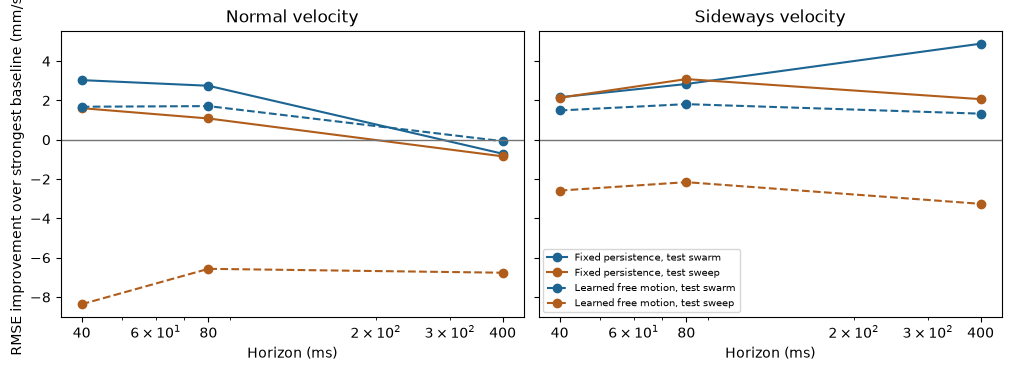

In [3]:
cols=["test","family","horizon","axis","model","rmse","worst_rmse","r2","worst_r2"]
display(scores.query("test=='recording' and model=='separate'")[cols].round(3).reset_index(drop=True))
def transfers(table):
    table=table.query("test=='cross-family'")
    by=table.pivot(index=["family","horizon","axis"],columns="model",values="rmse")
    reference=by[["free","free_clamp","history","baseline"]].min(axis=1)
    return pd.DataFrame({"best reference":reference,"horizon-specific RMSE":by.separate,
                         "horizon-specific gain":reference-by.separate,"log-time gain":reference-by.log_time})

gains=pd.concat({"Learned free motion":transfers(scores),"Fixed persistence (exploratory)":transfers(fixed)},
                names=["Free-motion model"])
display(gains.round(2))
common_benchmark = read('transfer_comparison').query("drive=='fixed' and model=='separate'")
print('Exploratory fixed-persistence fit against the strongest baseline from either free-motion analysis. Positive gain favors EPDE.')
display(common_benchmark[['family','axis','horizon','benchmark','benchmark_rmse','rmse','r2','gain_mm_s']].round(3))
fig,axes=plt.subplots(1,2,figsize=(10,3.6),sharey=True,layout="constrained")
for a,ax in zip(["n","t"],axes):
    for (model,family),g in gains.xs(a,level="axis").groupby(level=["Free-motion model","family"]):
        g=g.droplevel(["Free-motion model","family"]).sort_index()
        ax.plot(g.index,g["horizon-specific gain"],marker="o",linestyle="--" if model.startswith("Learned") else "-",
                color="#1c6592" if family=="swarm" else "#b05d1c",label=f"{model.split(' (')[0]}, test {family}")
    ax.axhline(0,color="0.45",lw=1)
    ax.set(xticks=[40,80,400],xscale="log",title={"n":"Normal velocity","t":"Sideways velocity"}[a],xlabel="Horizon (ms)")
    ax.set_xticks([40,80,400],labels=["40","80","400"])
axes[0].set_ylabel("RMSE improvement over strongest baseline (mm/s)")
axes[1].legend(fontsize=7)
plt.show()

### Uncertainty and controls

Positive gain means lower RMSE for the interaction equation. The 95% intervals resample ten-second blocks within each held recording, preserving simultaneous pair events; fits stay fixed. The “baseline minus separate” interval uses the baseline selected on the training validation tails. The family-transfer table above applies the stricter comparison against the lowest mean error among all three named baselines and that validation-selected baseline. Intervals describe these recordings. Independent replication must hold out newly acquired experiments.

In [4]:
ci=pd.concat({"Learned":read("paired_uncertainty"),"Fixed":read("fixed_drive_uncertainty")},names=["drive"])
display(ci.query("test=='cross-family' and comparison=='baseline minus separate'")
        [["family","axis","horizon","gain_mm_s","lower","upper","improved","recordings"]].round(2))
control=read("scores").query("test=='recording' and model in ['separate','baseline'] and cohort!='near'")
display(control.pivot(index=["family","cohort","axis","horizon","n"],columns="model",values="rmse").round(2))
ablation=fixed.query("test=='cross-family' and (model.str.startswith('without_') or model=='separate')",engine="python").pivot(
    index=["family","axis","horizon"],columns="model",values="rmse")
display(ablation.drop(columns="separate").subtract(ablation.separate,axis=0).round(2))
print("Ablation entries give the increase in mm/s when the indicated term group is removed and the front is reselected.")
slide=scores.query("test=='recording' and family=='swarm' and model in ['signed_slip','slip_reference']")
display(slide.pivot(index=["horizon","axis"],columns="model",values="rmse").round(3))

family axis  horizon  gain_mm_s  lower  upper  improved  recordings
drive                                                                         
Learned 0   swarm    n       40       1.68   1.39   1.97         4           5
        3   swarm    n       80       1.71   1.52   1.89         4           5
        6   swarm    n      400      -0.07  -0.22   0.08         3           5
        9   swarm    t       40       1.49   1.39   1.59         5           5
        12  swarm    t       80       1.81   1.72   1.91         5           5
        15  swarm    t      400       1.33   1.23   1.42         5           5
        18  sweep    n       40      -8.37  -8.67  -8.07         0           3
        21  sweep    n       80      -6.56  -6.81  -6.34         0           3
        24  sweep    n      400      -6.76  -7.08  -6.44         0           3
        27  sweep    t       40      -2.58  -2.82  -2.33         0           3
        30  sweep    t       80      -1.68  -1.93  -1.44         0           3
        33  sweep    t      400      -3.26  -3.60  -2.95         0           3
Fixed   0   swarm    n       40       3.03   2.77   3.30         5           5
        3   swarm    n       80       2.75   2.57   2.91         5           5
        6   swarm    n      400      -0.71  -0.84  -0.58         0           5
        9   swarm    t       40       2.16   1.99   2.35         5           5
        12  swarm    t       80       2.84   2.67   3.01         5           5
        15  swarm    t      400       4.89   4.67   5.10         5           5
        18  sweep    n       40       1.61   1.40   1.81         3           3
        21  sweep    n       80       1.08   0.93   1.22         3           3
        24  sweep    n      400      -0.84  -0.95  -0.72         1           3
        27  sweep    t       40       2.49   2.37   2.61         3           3
        30  sweep    t       80       3.39   3.23   3.55         3           3
        33  sweep    t      400       2.07   1.89   2.26         3           3

model                                      baseline  separate
family cohort          axis horizon n                        
swarm  already closing n    40      21780     33.86     32.80
                            80      21780     26.32     25.13
                            400     21780     12.65     13.43
                       t    40      21780     36.21     35.77
                            80      21780     33.26     32.60
...                                             ...       ...
sweep  matched near    n    80      11528     20.05     20.48
                            400     11528     14.26     13.82
                       t    40      11528     29.22     27.81
                            80      11528     27.97     25.93
                            400     11528     27.08     23.87

[66 rows x 2 columns]

model                without_clearance  without_history  without_spin_slide  \
family axis horizon                                                           
swarm  n    40                    7.01            -0.10                0.31   
            80                   11.04            -0.04               -0.04   
            400                  15.30             0.00                0.51   
       t    40                    0.08             0.14               -0.00   
            80                    0.26             0.17                0.01   
            400                   1.27             0.05                0.14   
sweep  n    40                    6.81            -0.17                0.23   
            80                   14.27            -0.27                0.00   
            400                  15.77            -0.03                0.57   
       t    40                   -0.19             0.13                0.02   
            80                   -0.03             0.31                0.20   
            400                   0.61             0.00                0.06   

model                without_third  
family axis horizon                 
swarm  n    40                0.40  
            80                0.15  
            400               0.49  
       t    40                0.81  
            80                1.26  
            400               2.09  
sweep  n    40                0.27  
            80                0.23  
            400               0.31  
       t    40                0.86  
            80                1.55  
            400               1.89

Ablation entries give the increase in mm/s when the indicated term group is removed and the front is reselected.


,model,signed_slip,slip_reference
horizon,axis,,
40,t,35.777,35.782
80,t,32.610,32.624
400,t,25.770,25.750


## Camera, rim and sampling checks

The older registrations tracked the static arena rim and evaluated the fit on withheld landmarks. Independently, six clips per old recording were chosen across apparent contact, clear-gap and uncertain labels. Radial intensity edges on unoccluded arcs give a robust fitted circle center for each visible robot. The rim correction measures how replacing the tracked marker by that center changes the pair’s projected speed. Its variability also includes rim-fitting error. The angular check uses the rotation of the square marker’s fourth angular harmonic on consecutive frames.

The 50 Hz series were also decimated to 25 Hz before detecting gates, fitting and testing. The paired check matches the redetected gates for the same recording, stage and robot IDs within 40 ms. Timing differences and changed incoming velocities both enter this sensitivity test. Optical contact status is assigned only after predictions are frozen, for the same old-video pair within two frames of the reviewed gate. Future contact, clearance or release was never required to enter the main comparison.

In [5]:
display(read("optical_audit").round(3))
down=read("sampling_sensitivity")
display(down.groupby(["axis","horizon"]).agg(matched_gates=("n","sum"),native_50_hz_rmse=("rmse50","mean"),
          downsampled_25_hz_rmse=("rmse25","mean")).round(2))
print("Disjoint matched near/distant controls:",len(pd.read_parquet(result/"matched_distant.parquet")))

,recording,horizon,registered_clips,rim_events,rim_poses,paired_rim_windows,median_marker_offset_px,median_rim_fit_error_px,registration_change_median_abs_mm_s,rim_change_median_abs_mm_s,median_ring_step_px,median_withheld_error_px,spin_checks,sign_agreements
0,N30_PWM10_D41,40,37,6,55,5,2.527,0.629,0.128,4.871,0.397,0.786,41,41
1,N30_PWM10_D41,80,37,6,55,5,2.527,0.629,0.071,3.582,0.397,0.786,41,41
2,N40_PWM10_D40,40,44,6,60,6,3.240,0.519,0.088,5.396,0.524,0.855,45,45
3,N40_PWM10_D40,80,44,6,60,6,3.240,0.519,0.087,3.153,0.524,0.855,45,45
4,N40_PWM10_D41,40,28,6,55,5,2.647,0.601,0.097,3.734,0.473,0.879,34,34
5,N40_PWM10_D41,80,28,6,55,5,2.647,0.601,0.040,2.197,0.473,0.879,34,34
6,N40_PWM20_D40,40,48,6,50,4,2.960,0.487,0.192,11.318,0.590,0.971,37,37
7,N40_PWM20_D40,80,48,6,50,4,2.960,0.487,0.125,6.003,0.590,0.971,37,37
8,N40_PWM20_D41,40,33,6,53,4,2.237,0.560,0.162,3.202,0.635,1.015,40,40
9,N40_PWM20_D41,80,33,6,53,4,2.237,0.560,0.120,4.178,0.635,1.015,40,40


matched_gates  native_50_hz_rmse  downsampled_25_hz_rmse
axis horizon                                                          
n    40               23542              26.44                   29.84
     80               23542              20.98                   22.38
     400              23542              14.26                   14.48
t    40               23542              28.24                   28.70
     80               23542              26.43                   26.58
     400              23542              24.33                   24.31

Disjoint matched near/distant controls: 20866


## Full Pareto fronts in mathematical notation

The default view displays every equation on the pooled primary and exploratory fronts. Each row has two coefficient sets. The **search equation** produced the displayed WAPE and dyadic instability on the balanced training screen. The **refit** uses all training-prefix events. In pooled tables, the error columns average the same fixed structure’s recording-held-out refits across all eight recordings, including folds where that structure missed the front. These values describe a structure chosen with access to all training prefixes. The separate model-selection results above give the held-out performance of the selection procedure.

Set the fold selector to a recording name or to <code>train_swarm</code> or <code>train_sweep</code> to inspect a training-only front and its actual held-out scores. A star identifies the validation choice. The log-time tables display one equation per support; the RMSE and $R^2$ triples are in 40, 80 and 400 ms order.

In [6]:
main_front=read("all_fronts")
fixed_front=read("fixed_drive_fronts")
terms_math={
    "n":[r"[-g/h-f_n]_+",r"zc",r"z\lvert s\rvert",r"zW",r"zLc",r"A_n"],
    "t":[r"zs",r"zsc",r"zIs",r"zsW",r"zLs",r"A_t"],
}
def math_eq(row,col):
    b=np.array(json.loads(row[col]))
    terms=[]
    for k,name in enumerate(terms_math[row.axis]):
        if not (int(row["mask"]) & (1<<k)):
            continue
        if row.timing=="log":
            terms.append(r"+\left("+f"{b[k]:.4g}{b[k+6]:+.4g}"+r"\log(h/0.08)\right)"+name)
        else:
            terms.append(f"{b[k]:+.4g}"+r"\,"+name)
    return "$"+r"\widehat u_"+row.axis+"=f_"+row.axis+"".join(terms)+"$"

show_fold="pooled"  # e.g. "N30_PWM10_D41", "Experiment_1", "train_swarm"
for study,table in [("Learned free motion",main_front),("Fixed persistence, exploratory",fixed_front)]:
    chosen=table[(table.fold==show_fold)&(table["mode"]=="native")].copy()
    for (held,axis,timing),part in chosen.groupby(["held","axis","timing"]):
        for window,group in part.groupby(part.horizon if timing=="separate" else np.zeros(len(part),int)):
            label=f"{window} ms" if timing=="separate" else "shared time dependence"
            lines=["| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | "+r"$R^2$ |",
                   "|---|---|---:|---:|---|---:|---:|"]
            for mask,g in group.sort_values("wape").groupby("mask",sort=False):
                g=g.sort_values("horizon"); row=g.iloc[0]
                rmse,r2=(("fixed_support_mean_rmse","fixed_support_mean_r2") if held=="pooled" else ("rmse_mm_s","r2"))
                values=lambda col:", ".join(f"{v:.3f}" for v in g[col])
                mark="★" if row.selected else ""
                lines.append(f"| {mark} | {math_eq(row,'screen_coeff')} | {row.wape:.4f} | {row.dyad:.3f} | "
                             f"{math_eq(row,'coeff')} | {values(rmse)} | {values(r2)} |")
            display(Markdown(f"#### {study} · {held} · {axis} · {label}\n\n"+"\n".join(lines)))

#### Learned free motion · pooled · n · shared time dependence

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_n=f_n+\left(1.277-0.2721\log(h/0.08)\right)[-g/h-f_n]_++\left(0.3732-0.1024\log(h/0.08)\right)zc+\left(-0.1386+0.09933\log(h/0.08)\right)z\lvert s\rvert+\left(-0.06705+0.04005\log(h/0.08)\right)zW+\left(0.3042-0.03884\log(h/0.08)\right)zLc+\left(0.464-0.1426\log(h/0.08)\right)A_n$ | 0.6420 | 13.323 | $\widehat u_n=f_n+\left(1.32-0.3054\log(h/0.08)\right)[-g/h-f_n]_++\left(0.3679-0.1046\log(h/0.08)\right)zc+\left(-0.09435+0.07392\log(h/0.08)\right)z\lvert s\rvert+\left(-0.04678+0.02698\log(h/0.08)\right)zW+\left(0.2074+0.05479\log(h/0.08)\right)zLc+\left(0.3871-0.07972\log(h/0.08)\right)A_n$ | 30.668, 24.093, 13.964 | 0.014, -0.043, -0.103 |
|  | $\widehat u_n=f_n+\left(1.312-0.2931\log(h/0.08)\right)[-g/h-f_n]_++\left(0.333-0.07591\log(h/0.08)\right)zc+\left(-0.07724+0.04747\log(h/0.08)\right)zW+\left(0.2805-0.02078\log(h/0.08)\right)zLc+\left(0.5087-0.1752\log(h/0.08)\right)A_n$ | 0.6478 | 11.914 | $\widehat u_n=f_n+\left(1.337-0.3167\log(h/0.08)\right)[-g/h-f_n]_++\left(0.3423-0.08549\log(h/0.08)\right)zc+\left(-0.053+0.03189\log(h/0.08)\right)zW+\left(0.1911+0.06859\log(h/0.08)\right)zLc+\left(0.4129-0.1002\log(h/0.08)\right)A_n$ | 30.832, 24.129, 13.966 | 0.003, -0.047, -0.103 |
|  | $\widehat u_n=f_n+\left(1.26-0.2495\log(h/0.08)\right)[-g/h-f_n]_++\left(0.4186-0.08106\log(h/0.08)\right)zc+\left(-0.1674+0.1282\log(h/0.08)\right)z\lvert s\rvert+\left(0.4404-0.1717\log(h/0.08)\right)A_n$ | 0.6484 | 7.925 | $\widehat u_n=f_n+\left(1.323-0.294\log(h/0.08)\right)[-g/h-f_n]_++\left(0.3929-0.05871\log(h/0.08)\right)zc+\left(-0.1149+0.1002\log(h/0.08)\right)z\lvert s\rvert+\left(0.3665-0.1179\log(h/0.08)\right)A_n$ | 30.938, 24.217, 14.182 | -0.004, -0.054, -0.139 |
|  | $\widehat u_n=f_n+\left(1.271-0.255\log(h/0.08)\right)[-g/h-f_n]_++\left(0.438-0.09205\log(h/0.08)\right)zc+\left(-0.06656+0.04737\log(h/0.08)\right)zW+\left(0.4346-0.1727\log(h/0.08)\right)A_n$ | 0.6493 | 7.834 | $\widehat u_n=f_n+\left(1.316-0.2888\log(h/0.08)\right)[-g/h-f_n]_++\left(0.4122-0.06831\log(h/0.08)\right)zc+\left(-0.04605+0.03515\log(h/0.08)\right)zW+\left(0.3624-0.1199\log(h/0.08)\right)A_n$ | 30.828, 24.200, 14.193 | 0.003, -0.052, -0.140 |
|  | $\widehat u_n=f_n+\left(1.321-0.2841\log(h/0.08)\right)[-g/h-f_n]_++\left(0.3992-0.07638\log(h/0.08)\right)zc+\left(-0.0795+0.05241\log(h/0.08)\right)zW$ | 0.6559 | 3.373 | $\widehat u_n=f_n+\left(1.346-0.3103\log(h/0.08)\right)[-g/h-f_n]_++\left(0.3792-0.0554\log(h/0.08)\right)zc+\left(-0.05498+0.03789\log(h/0.08)\right)zW$ | 31.139, 24.295, 14.331 | -0.016, -0.062, -0.165 |
|  | $\widehat u_n=f_n+\left(1.828-0.3799\log(h/0.08)\right)[-g/h-f_n]_++\left(0.08832+0.0449\log(h/0.08)\right)z\lvert s\rvert$ | 0.6949 | 2.953 | $\widehat u_n=f_n+\left(1.835-0.3841\log(h/0.08)\right)[-g/h-f_n]_++\left(0.1558+0.02445\log(h/0.08)\right)z\lvert s\rvert$ | 32.582, 26.628, 15.027 | -0.114, -0.296, -0.263 |
|  | $\widehat u_n=f_n+\left(1.885-0.3417\log(h/0.08)\right)[-g/h-f_n]_+$ | 0.6997 | 0.609 | $\widehat u_n=f_n+\left(1.939-0.3596\log(h/0.08)\right)[-g/h-f_n]_+$ | 32.557, 27.316, 15.420 | -0.113, -0.367, -0.324 |

#### Learned free motion · pooled · n · 40 ms

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_n=f_n+1.467\,[-g/h-f_n]_++0.4189\,zc-0.2548\,z\lvert s\rvert-0.09461\,zW+0.3216\,zLc+0.6238\,A_n$ | 0.8480 | 7.939 | $\widehat u_n=f_n+1.537\,[-g/h-f_n]_++0.4248\,zc-0.1674\,z\lvert s\rvert-0.07348\,zW+0.1274\,zLc+0.5043\,A_n$ | 30.519 | 0.024 |
|  | $\widehat u_n=f_n+1.402\,[-g/h-f_n]_++0.5356\,zc-0.2421\,z\lvert s\rvert-0.08345\,zW+0.544\,A_n$ | 0.8496 | 3.336 | $\widehat u_n=f_n+1.517\,[-g/h-f_n]_++0.4702\,zc-0.1617\,z\lvert s\rvert-0.06932\,zW+0.4722\,A_n$ | 30.514 | 0.025 |
|  | $\widehat u_n=f_n+1.437\,[-g/h-f_n]_++0.4436\,zc-0.3036\,z\lvert s\rvert+0.6225\,A_n$ | 0.8581 | 1.859 | $\widehat u_n=f_n+1.559\,[-g/h-f_n]_++0.3899\,zc-0.2146\,z\lvert s\rvert+0.5277\,A_n$ | 30.788 | 0.006 |
|  | $\widehat u_n=f_n+1.473\,[-g/h-f_n]_++0.4546\,zc-0.1032\,zW+0.6348\,A_n$ | 0.8621 | 1.500 | $\widehat u_n=f_n+1.552\,[-g/h-f_n]_++0.4178\,zc-0.08118\,zW+0.5247\,A_n$ | 30.680 | 0.013 |
|  | $\widehat u_n=f_n+1.509\,[-g/h-f_n]_++0.3945\,zc-0.3664\,z\lvert s\rvert$ | 0.8729 | 1.206 | $\widehat u_n=f_n+1.609\,[-g/h-f_n]_++0.3461\,zc-0.2643\,z\lvert s\rvert$ | 31.111 | -0.013 |
|  | $\widehat u_n=f_n+1.556\,[-g/h-f_n]_++0.4026\,zc-0.1225\,zW$ | 0.8738 | 0.976 | $\widehat u_n=f_n+1.604\,[-g/h-f_n]_++0.3717\,zc-0.09429\,zW$ | 31.004 | -0.006 |
|  | $\widehat u_n=f_n+2.06\,[-g/h-f_n]_+$ | 0.9079 | 0.299 | $\widehat u_n=f_n+2.126\,[-g/h-f_n]_+$ | 32.555 | -0.114 |

#### Learned free motion · pooled · n · 80 ms

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_n=f_n+1.013\,[-g/h-f_n]_++0.6154\,zc-0.08256\,z\lvert s\rvert-0.06154\,zW+0.334\,A_n$ | 0.6118 | 8.259 | $\widehat u_n=f_n+1.064\,[-g/h-f_n]_++0.5684\,zc-0.07065\,z\lvert s\rvert-0.03295\,zW+0.2576\,A_n$ | 23.654 | -0.001 |
|  | $\widehat u_n=f_n+1.041\,[-g/h-f_n]_++0.5812\,zc-0.06773\,zW+0.362\,A_n$ | 0.6160 | 3.459 | $\widehat u_n=f_n+1.082\,[-g/h-f_n]_++0.5416\,zc-0.03775\,zW+0.2791\,A_n$ | 23.693 | -0.005 |
|  | $\widehat u_n=f_n+1.051\,[-g/h-f_n]_++0.5889\,zc-0.1076\,z\lvert s\rvert-0.06854\,zW$ | 0.6161 | 2.178 | $\widehat u_n=f_n+1.086\,[-g/h-f_n]_++0.5481\,zc-0.08977\,z\lvert s\rvert-0.03735\,zW$ | 23.764 | -0.010 |
|  | $\widehat u_n=f_n+1.093\,[-g/h-f_n]_++0.5402\,zc-0.0776\,zW$ | 0.6222 | 1.513 | $\widehat u_n=f_n+1.111\,[-g/h-f_n]_++0.511\,zc-0.04406\,zW$ | 23.829 | -0.017 |
|  | $\widehat u_n=f_n+1.103\,[-g/h-f_n]_++0.495\,zc-0.1598\,z\lvert s\rvert$ | 0.6266 | 1.233 | $\widehat u_n=f_n+1.12\,[-g/h-f_n]_++0.4948\,zc-0.1185\,z\lvert s\rvert$ | 23.865 | -0.020 |
|  | $\widehat u_n=f_n+1.104\,[-g/h-f_n]_++0.47\,zc+0.4403\,A_n$ | 0.6274 | 0.950 | $\widehat u_n=f_n+1.122\,[-g/h-f_n]_++0.4773\,zc+0.3164\,A_n$ | 23.804 | -0.016 |
|  | $\widehat u_n=f_n+1.181\,[-g/h-f_n]_++0.3981\,zc$ | 0.6382 | 0.358 | $\widehat u_n=f_n+1.164\,[-g/h-f_n]_++0.4294\,zc$ | 23.985 | -0.032 |
|  | $\widehat u_n=f_n+1.549\,[-g/h-f_n]_++0.5466\,zLc$ | 0.6597 | 0.295 | $\widehat u_n=f_n+1.552\,[-g/h-f_n]_++0.6164\,zLc$ | 24.909 | -0.121 |
|  | $\widehat u_n=f_n+1.917\,[-g/h-f_n]_+$ | 0.7026 | 0.090 | $\widehat u_n=f_n+1.969\,[-g/h-f_n]_+$ | 27.310 | -0.365 |

#### Learned free motion · pooled · n · 400 ms

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_n=f_n+0.9307\,[-g/h-f_n]_++0.1643\,zc+0.003962\,z\lvert s\rvert+0.2209\,zLc+0.258\,A_n$ | 0.4165 | 5.032 | $\widehat u_n=f_n+0.9323\,[-g/h-f_n]_++0.1553\,zc+0.01718\,z\lvert s\rvert+0.2556\,zLc+0.2913\,A_n$ | 13.834 | -0.074 |
|  | $\widehat u_n=f_n+0.9301\,[-g/h-f_n]_++0.1656\,zc+0.2224\,zLc+0.2565\,A_n$ | 0.4166 | 2.631 | $\widehat u_n=f_n+0.9294\,[-g/h-f_n]_++0.1609\,zc+0.2613\,zLc+0.2856\,A_n$ | 13.839 | -0.075 |
|  | $\widehat u_n=f_n+0.9474\,[-g/h-f_n]_++0.2482\,zc+0.1796\,A_n$ | 0.4217 | 1.134 | $\widehat u_n=f_n+0.946\,[-g/h-f_n]_++0.2609\,zc+0.2014\,A_n$ | 14.079 | -0.115 |
|  | $\widehat u_n=f_n+0.95\,[-g/h-f_n]_++0.2267\,zc$ | 0.4266 | 0.400 | $\widehat u_n=f_n+0.9413\,[-g/h-f_n]_++0.2389\,zc$ | 14.216 | -0.138 |
|  | $\widehat u_n=f_n+1.06\,[-g/h-f_n]_++0.3527\,zLc$ | 0.4322 | 0.389 | $\widehat u_n=f_n+1.044\,[-g/h-f_n]_++0.3914\,zLc$ | 14.337 | -0.150 |
|  | $\widehat u_n=f_n+1.329\,[-g/h-f_n]_+$ | 0.4548 | 0.044 | $\widehat u_n=f_n+1.354\,[-g/h-f_n]_+$ | 15.420 | -0.324 |

#### Learned free motion · pooled · t · shared time dependence

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_t=f_t+\left(0.3215-0.126\log(h/0.08)\right)zs+\left(-0.1298+0.03035\log(h/0.08)\right)zsc+\left(-0.0138-0.03906\log(h/0.08)\right)zIs+\left(-0.0254+0.03683\log(h/0.08)\right)zsW+\left(-0.5907+0.1566\log(h/0.08)\right)zLs+\left(0.6311+0.04343\log(h/0.08)\right)A_t$ | 0.9585 | 61.454 | $\widehat u_t=f_t+\left(0.1393+0.02295\log(h/0.08)\right)zs+\left(-0.07963-0.002116\log(h/0.08)\right)zsc+\left(0.01697-0.05261\log(h/0.08)\right)zIs+\left(-0.02126+0.01947\log(h/0.08)\right)zsW+\left(-0.4575+0.03049\log(h/0.08)\right)zLs+\left(0.6472+0.01675\log(h/0.08)\right)A_t$ | 33.021, 30.289, 25.162 | 0.304, 0.303, 0.108 |
|  | $\widehat u_t=f_t+\left(0.3218-0.1251\log(h/0.08)\right)zs+\left(-0.1298+0.03037\log(h/0.08)\right)zsc+\left(-0.02881+0.02719\log(h/0.08)\right)zsW+\left(-0.5899+0.1589\log(h/0.08)\right)zLs+\left(0.6316+0.04494\log(h/0.08)\right)A_t$ | 0.9588 | 37.923 | $\widehat u_t=f_t+\left(0.1389+0.02403\log(h/0.08)\right)zs+\left(-0.08017-0.0004505\log(h/0.08)\right)zsc+\left(-0.01726+0.007061\log(h/0.08)\right)zsW+\left(-0.4572+0.02965\log(h/0.08)\right)zLs+\left(0.6473+0.01659\log(h/0.08)\right)A_t$ | 33.017, 30.282, 25.150 | 0.304, 0.303, 0.109 |
|  | $\widehat u_t=f_t+\left(0.2751-0.08107\log(h/0.08)\right)zs+\left(-0.1349+0.03524\log(h/0.08)\right)zsc+\left(-0.6015+0.1699\log(h/0.08)\right)zLs+\left(0.6366+0.04023\log(h/0.08)\right)A_t$ | 0.9597 | 33.972 | $\widehat u_t=f_t+\left(0.1073+0.03698\log(h/0.08)\right)zs+\left(-0.08392+0.001087\log(h/0.08)\right)zsc+\left(-0.4587+0.03026\log(h/0.08)\right)zLs+\left(0.647+0.01671\log(h/0.08)\right)A_t$ | 33.034, 30.296, 25.150 | 0.303, 0.303, 0.109 |
|  | $\widehat u_t=f_t+\left(-0.02267+0.02084\log(h/0.08)\right)zsW+\left(-0.3083+0.03775\log(h/0.08)\right)zLs+\left(0.6211+0.05071\log(h/0.08)\right)A_t$ | 0.9619 | 21.501 | $\widehat u_t=f_t+\left(-0.02011+0.00952\log(h/0.08)\right)zsW+\left(-0.3492+0.05602\log(h/0.08)\right)zLs+\left(0.6466+0.01466\log(h/0.08)\right)A_t$ | 33.001, 30.274, 25.139 | 0.305, 0.304, 0.110 |
|  | $\widehat u_t=f_t+\left(-0.02631+0.003227\log(h/0.08)\right)zsc+\left(-0.343+0.09376\log(h/0.08)\right)zLs+\left(0.6253+0.04355\log(h/0.08)\right)A_t$ | 0.9620 | 19.100 | $\widehat u_t=f_t+\left(-0.0416+0.01568\log(h/0.08)\right)zsc+\left(-0.3579+0.06502\log(h/0.08)\right)zLs+\left(0.6433+0.01546\log(h/0.08)\right)A_t$ | 33.036, 30.306, 25.175 | 0.303, 0.302, 0.108 |
|  | $\widehat u_t=f_t+\left(-0.3732+0.09746\log(h/0.08)\right)zLs+\left(0.6295+0.04304\log(h/0.08)\right)A_t$ | 0.9624 | 13.325 | $\widehat u_t=f_t+\left(-0.4088+0.08424\log(h/0.08)\right)zLs+\left(0.6509+0.0126\log(h/0.08)\right)A_t$ | 33.003, 30.274, 25.125 | 0.304, 0.304, 0.111 |
|  | $\widehat u_t=f_t+\left(-0.1799+0.0288\log(h/0.08)\right)zs+\left(-0.08301+0.05884\log(h/0.08)\right)zIs+\left(0.6363+0.0429\log(h/0.08)\right)A_t$ | 0.9643 | 12.685 | $\widehat u_t=f_t+\left(-0.2264+0.05601\log(h/0.08)\right)zs+\left(-0.04097-0.001137\log(h/0.08)\right)zIs+\left(0.6511+0.01623\log(h/0.08)\right)A_t$ | 33.172, 30.445, 25.255 | 0.298, 0.296, 0.103 |
|  | $\widehat u_t=f_t+\left(-0.05705-0.009022\log(h/0.08)\right)zsc+\left(-0.05911+0.03008\log(h/0.08)\right)zsW+\left(0.668+0.04188\log(h/0.08)\right)A_t$ | 0.9652 | 11.008 | $\widehat u_t=f_t+\left(-0.07944+0.01629\log(h/0.08)\right)zsc+\left(-0.05138+0.01343\log(h/0.08)\right)zsW+\left(0.6934+0.00802\log(h/0.08)\right)A_t$ | 33.272, 30.542, 25.289 | 0.292, 0.290, 0.098 |
|  | $\widehat u_t=f_t+\left(-0.07611+0.02739\log(h/0.08)\right)zsW+\left(0.679+0.04362\log(h/0.08)\right)A_t$ | 0.9663 | 8.405 | $\widehat u_t=f_t+\left(-0.07618+0.01851\log(h/0.08)\right)zsW+\left(0.7127+0.004057\log(h/0.08)\right)A_t$ | 33.261, 30.534, 25.244 | 0.292, 0.290, 0.099 |
|  | $\widehat u_t=f_t+\left(-0.2559+0.08651\log(h/0.08)\right)zIs+\left(0.7049+0.03191\log(h/0.08)\right)A_t$ | 0.9673 | 5.908 | $\widehat u_t=f_t+\left(-0.2598+0.05299\log(h/0.08)\right)zIs+\left(0.7435-0.006639\log(h/0.08)\right)A_t$ | 33.369, 30.642, 25.246 | 0.287, 0.284, 0.097 |
|  | $\widehat u_t=f_t+\left(0.816-0.005684\log(h/0.08)\right)A_t$ | 0.9758 | 5.388 | $\widehat u_t=f_t+\left(0.8258-0.02342\log(h/0.08)\right)A_t$ | 33.649, 30.897, 25.306 | 0.274, 0.270, 0.086 |
|  | $\widehat u_t=f_t+\left(-0.09507+0.02617\log(h/0.08)\right)zsW$ | 0.9858 | 5.212 | $\widehat u_t=f_t+\left(-0.09333+0.01842\log(h/0.08)\right)zsW$ | 33.736, 31.267, 26.041 | 0.272, 0.255, 0.042 |
|  | $\widehat u_t=f_t+\left(-0.1851+0.03444\log(h/0.08)\right)zsc$ | 0.9908 | 4.520 | $\widehat u_t=f_t+\left(-0.1981+0.0367\log(h/0.08)\right)zsc$ | 33.907, 31.417, 26.135 | 0.266, 0.249, 0.037 |

#### Learned free motion · pooled · t · 40 ms

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_t=f_t+0.359\,zs-0.1349\,zsc-0.05148\,zsW-0.6339\,zLs+0.5596\,A_t$ | 0.9638 | 20.331 | $\widehat u_t=f_t+0.1129\,zs-0.07221\,zsc-0.02054\,zsW-0.46\,zLs+0.5922\,A_t$ | 32.989 | 0.305 |
|  | $\widehat u_t=f_t+0.2756\,zs-0.1441\,zsc-0.6548\,zLs+0.5685\,A_t$ | 0.9649 | 9.637 | $\widehat u_t=f_t+0.07523\,zs-0.07668\,zsc-0.4618\,zLs+0.5919\,A_t$ | 33.005 | 0.304 |
|  | $\widehat u_t=f_t-0.0003675\,zsc-0.0426\,zsW-0.3137\,zLs+0.547\,A_t$ | 0.9662 | 8.359 | $\widehat u_t=f_t-0.03029\,zsc-0.01775\,zsW-0.3589\,zLs+0.5885\,A_t$ | 32.998 | 0.305 |
|  | $\widehat u_t=f_t-0.04267\,zsW-0.3139\,zLs+0.547\,A_t$ | 0.9662 | 3.261 | $\widehat u_t=f_t-0.02442\,zsW-0.3763\,zLs+0.5926\,A_t$ | 32.975 | 0.306 |
|  | $\widehat u_t=f_t-0.1281\,zIs-0.3574\,zLs+0.5464\,A_t$ | 0.9665 | 3.155 | $\widehat u_t=f_t-0.05661\,zIs-0.412\,zLs+0.5957\,A_t$ | 32.976 | 0.306 |
|  | $\widehat u_t=f_t-0.4361\,zLs+0.5627\,A_t$ | 0.9670 | 1.547 | $\widehat u_t=f_t-0.4487\,zLs+0.5979\,A_t$ | 32.977 | 0.305 |
|  | $\widehat u_t=f_t-0.257\,zs+0.5755\,A_t$ | 0.9700 | 1.265 | $\widehat u_t=f_t-0.2711\,zs+0.5961\,A_t$ | 33.143 | 0.299 |
|  | $\widehat u_t=f_t-0.09709\,zsW+0.606\,A_t$ | 0.9701 | 1.233 | $\widehat u_t=f_t-0.08482\,zsW+0.6639\,A_t$ | 33.237 | 0.293 |
|  | $\widehat u_t=f_t-0.3295\,zIs+0.6376\,A_t$ | 0.9725 | 1.227 | $\widehat u_t=f_t-0.2853\,zIs+0.6994\,A_t$ | 33.346 | 0.288 |
|  | $\widehat u_t=f_t-0.5072\,zLs$ | 0.9765 | 0.843 | $\widehat u_t=f_t-0.5237\,zLs$ | 33.366 | 0.289 |
|  | $\widehat u_t=f_t-0.306\,zs$ | 0.9821 | 0.778 | $\widehat u_t=f_t-0.3211\,zs$ | 33.553 | 0.282 |
|  | $\widehat u_t=f_t+0.7808\,A_t$ | 0.9851 | 0.559 | $\widehat u_t=f_t+0.7898\,A_t$ | 33.628 | 0.275 |

... (6 outputs left out)

#### Fixed persistence, exploratory · pooled · t · shared time dependence

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_t=f_t+\left(-0.09445-0.343\log(h/0.08)\right)zs+\left(-0.1054+0.03955\log(h/0.08)\right)zsc+\left(0.06313+0.06576\log(h/0.08)\right)zIs+\left(-0.05982-0.00372\log(h/0.08)\right)zsW+\left(-0.5189+0.1736\log(h/0.08)\right)zLs+\left(0.8528+0.1437\log(h/0.08)\right)A_t$ | 0.7925 | 53.739 | $\widehat u_t=f_t+\left(-0.3451-0.2399\log(h/0.08)\right)zs+\left(-0.03256+0.02145\log(h/0.08)\right)zsc+\left(0.1059+0.05942\log(h/0.08)\right)zIs+\left(-0.04539-0.01976\log(h/0.08)\right)zsW+\left(-0.3558+0.08768\log(h/0.08)\right)zLs+\left(0.8887+0.1187\log(h/0.08)\right)A_t$ | 32.830, 30.115, 24.680 | 0.313, 0.315, 0.197 |
|  | $\widehat u_t=f_t+\left(-0.09588-0.3445\log(h/0.08)\right)zs+\left(-0.1054+0.0395\log(h/0.08)\right)zsc+\left(-0.04424+0.01251\log(h/0.08)\right)zsW+\left(-0.5227+0.1697\log(h/0.08)\right)zLs+\left(0.8504+0.1411\log(h/0.08)\right)A_t$ | 0.7926 | 30.607 | $\widehat u_t=f_t+\left(-0.3473-0.2411\log(h/0.08)\right)zs+\left(-0.03591+0.01957\log(h/0.08)\right)zsc+\left(-0.02042-0.00575\log(h/0.08)\right)zsW+\left(-0.3541+0.08864\log(h/0.08)\right)zLs+\left(0.889+0.1189\log(h/0.08)\right)A_t$ | 32.832, 30.128, 24.757 | 0.313, 0.315, 0.192 |
|  | $\widehat u_t=f_t+\left(-0.2922-0.2709\log(h/0.08)\right)zs+\left(-0.04567+0.01304\log(h/0.08)\right)zsW+\left(-0.3661+0.111\log(h/0.08)\right)zLs+\left(0.8462+0.1427\log(h/0.08)\right)A_t$ | 0.7932 | 25.690 | $\widehat u_t=f_t+\left(-0.4164-0.2034\log(h/0.08)\right)zs+\left(-0.02096-0.005453\log(h/0.08)\right)zsW+\left(-0.2981+0.05811\log(h/0.08)\right)zLs+\left(0.8881+0.1193\log(h/0.08)\right)A_t$ | 32.838, 30.134, 24.756 | 0.312, 0.314, 0.192 |
|  | $\widehat u_t=f_t+\left(-0.1413-0.08953\log(h/0.08)\right)zsc+\left(-0.04662+0.003979\log(h/0.08)\right)zsW+\left(-0.6082-0.1375\log(h/0.08)\right)zLs+\left(0.8538+0.1532\log(h/0.08)\right)A_t$ | 0.7942 | 22.037 | $\widehat u_t=f_t+\left(-0.1649-0.06994\log(h/0.08)\right)zsc+\left(-0.029-0.01171\log(h/0.08)\right)zsW+\left(-0.665-0.1272\log(h/0.08)\right)zLs+\left(0.9003+0.1267\log(h/0.08)\right)A_t$ | 32.832, 30.119, 25.048 | 0.313, 0.315, 0.171 |
|  | $\widehat u_t=f_t+\left(-0.5533-0.196\log(h/0.08)\right)zs+\left(0.0478-0.01023\log(h/0.08)\right)zsc+\left(-0.04742+0.01354\log(h/0.08)\right)zsW+\left(0.8524+0.1405\log(h/0.08)\right)A_t$ | 0.7957 | 18.054 | $\widehat u_t=f_t+\left(-0.6618-0.1624\log(h/0.08)\right)zs+\left(0.06978-0.006883\log(h/0.08)\right)zsc+\left(-0.02082-0.005648\log(h/0.08)\right)zsW+\left(0.8898+0.1187\log(h/0.08)\right)A_t$ | 32.921, 30.222, 24.784 | 0.309, 0.311, 0.191 |
|  | $\widehat u_t=f_t+\left(-0.5057-0.2062\log(h/0.08)\right)zs+\left(-0.04704+0.01346\log(h/0.08)\right)zsW+\left(0.8563+0.1397\log(h/0.08)\right)A_t$ | 0.7963 | 8.957 | $\widehat u_t=f_t+\left(-0.5914-0.1693\log(h/0.08)\right)zs+\left(-0.01907-0.005821\log(h/0.08)\right)zsW+\left(0.8934+0.1183\log(h/0.08)\right)A_t$ | 32.943, 30.241, 24.786 | 0.308, 0.310, 0.191 |
|  | $\widehat u_t=f_t+\left(-0.5587-0.2039\log(h/0.08)\right)zs+\left(-0.09662+0.05653\log(h/0.08)\right)zIs+\left(0.8566+0.1418\log(h/0.08)\right)A_t$ | 0.7976 | 6.972 | $\widehat u_t=f_t+\left(-0.6249-0.1851\log(h/0.08)\right)zs+\left(-0.01504+0.007601\log(h/0.08)\right)zIs+\left(0.893+0.1181\log(h/0.08)\right)A_t$ | 32.955, 30.258, 24.838 | 0.307, 0.309, 0.187 |
|  | $\widehat u_t=f_t+\left(-0.6016-0.1787\log(h/0.08)\right)zs+\left(0.8643+0.1374\log(h/0.08)\right)A_t$ | 0.7987 | 4.255 | $\widehat u_t=f_t+\left(-0.6317-0.1816\log(h/0.08)\right)zs+\left(0.8929+0.1181\log(h/0.08)\right)A_t$ | 32.955, 30.256, 24.834 | 0.307, 0.309, 0.187 |
|  | $\widehat u_t=f_t+\left(-0.9037-0.2287\log(h/0.08)\right)zLs+\left(0.8931+0.1658\log(h/0.08)\right)A_t$ | 0.8113 | 2.884 | $\widehat u_t=f_t+\left(-0.953-0.2476\log(h/0.08)\right)zLs+\left(0.9367+0.142\log(h/0.08)\right)A_t$ | 33.015, 30.409, 26.542 | 0.305, 0.301, 0.060 |
|  | $\widehat u_t=f_t+\left(-0.6753-0.1904\log(h/0.08)\right)zs$ | 0.8299 | 0.578 | $\widehat u_t=f_t+\left(-0.7067-0.1915\log(h/0.08)\right)zs$ | 33.667, 31.318, 26.675 | 0.279, 0.261, 0.060 |

#### Fixed persistence, exploratory · pooled · t · 40 ms

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_t=f_t+0.06085\,zs-0.1164\,zsc+0.009819\,zIs-0.06239\,zsW-0.5703\,zLs+0.7355\,A_t$ | 0.8884 | 25.134 | $\widehat u_t=f_t-0.2321\,zs-0.03564\,zsc+0.07504\,zIs-0.03568\,zsW-0.3837\,zLs+0.7861\,A_t$ | 32.822 | 0.313 |
|  | $\widehat u_t=f_t+0.06063\,zs-0.1164\,zsc-0.05997\,zsW-0.5709\,zLs+0.7352\,A_t$ | 0.8885 | 17.372 | $\widehat u_t=f_t-0.2337\,zs-0.03801\,zsc-0.01798\,zsW-0.3825\,zLs+0.7864\,A_t$ | 32.826 | 0.313 |
|  | $\widehat u_t=f_t+0.01588\,zIs-0.08083\,zsW-0.5698\,zLs+0.7415\,A_t$ | 0.8896 | 13.894 | $\widehat u_t=f_t+0.1114\,zIs-0.07647\,zsW-0.6604\,zLs+0.8098\,A_t$ | 32.894 | 0.310 |
|  | $\widehat u_t=f_t-0.07695\,zsW-0.5712\,zLs+0.741\,A_t$ | 0.8896 | 2.667 | $\widehat u_t=f_t-0.05123\,zsW-0.6632\,zLs+0.8108\,A_t$ | 32.906 | 0.309 |
|  | $\widehat u_t=f_t-0.3882\,zs-0.06303\,zsW+0.7415\,A_t$ | 0.8931 | 1.954 | $\widehat u_t=f_t-0.4965\,zs-0.01651\,zsW+0.7912\,A_t$ | 32.935 | 0.308 |
|  | $\widehat u_t=f_t-0.447\,zs-0.1569\,zIs+0.7398\,A_t$ | 0.8936 | 1.720 | $\widehat u_t=f_t-0.5223\,zs-0.02032\,zIs+0.7909\,A_t$ | 32.947 | 0.308 |
|  | $\widehat u_t=f_t-0.5168\,zs+0.7522\,A_t$ | 0.8958 | 0.688 | $\widehat u_t=f_t-0.5315\,zs+0.7907\,A_t$ | 32.947 | 0.308 |
|  | $\widehat u_t=f_t-0.8888\,zLs$ | 0.9154 | 0.236 | $\widehat u_t=f_t-0.9183\,zLs$ | 33.745 | 0.275 |

#### Fixed persistence, exploratory · pooled · t · 80 ms

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_t=f_t+0.0218\,zs-0.1289\,zsc-0.03415\,zsW-0.622\,zLs+0.8753\,A_t$ | 0.8555 | 11.663 | $\widehat u_t=f_t-0.2708\,zs-0.05231\,zsc-0.01819\,zsW-0.4014\,zLs+0.918\,A_t$ | 30.112 | 0.315 |
|  | $\widehat u_t=f_t-0.1208\,zsc-0.03361\,zsW-0.6026\,zLs+0.8745\,A_t$ | 0.8555 | 5.686 | $\widehat u_t=f_t-0.1528\,zsc-0.02489\,zsW-0.6438\,zLs+0.9268\,A_t$ | 30.112 | 0.315 |
|  | $\widehat u_t=f_t-0.1483\,zsc-0.6674\,zLs+0.8826\,A_t$ | 0.8578 | 2.022 | $\widehat u_t=f_t-0.1763\,zsc-0.6889\,zLs+0.9279\,A_t$ | 30.137 | 0.314 |
|  | $\widehat u_t=f_t-0.8373\,zLs+0.9059\,A_t$ | 0.8630 | 0.868 | $\widehat u_t=f_t-0.9049\,zLs+0.9601\,A_t$ | 30.406 | 0.301 |
|  | $\widehat u_t=f_t-0.1741\,zsW+1.011\,A_t$ | 0.8842 | 0.792 | $\widehat u_t=f_t-0.176\,zsW+1.086\,A_t$ | 31.477 | 0.248 |
|  | $\widehat u_t=f_t-0.6215\,zs$ | 0.8924 | 0.250 | $\widehat u_t=f_t-0.6725\,zs$ | 31.300 | 0.262 |
|  | $\widehat u_t=f_t-0.9517\,zLs$ | 0.8953 | 0.229 | $\widehat u_t=f_t-1.026\,zLs$ | 31.499 | 0.251 |
|  | $\widehat u_t=f_t-0.4383\,zsc$ | 0.9316 | 0.220 | $\widehat u_t=f_t-0.4601\,zsc$ | 32.801 | 0.186 |

#### Fixed persistence, exploratory · pooled · t · 400 ms

| Choice | Search equation | WAPE | Dyadic | Refit equation | RMSE (mm/s) | $R^2$ |
|---|---|---:|---:|---|---:|---:|
| ★ | $\widehat u_t=f_t-0.682\,zs-0.03465\,zsc+0.1656\,zIs-0.06802\,zsW-0.2099\,zLs+1.076\,A_t$ | 0.6374 | 23.818 | $\widehat u_t=f_t-0.7541\,zs+0.007048\,zsc+0.206\,zIs-0.07892\,zsW-0.2005\,zLs+1.071\,A_t$ | 24.671 | 0.198 |
|  | $\widehat u_t=f_t-0.8384\,zs+0.1733\,zIs-0.07097\,zsW+1.08\,A_t$ | 0.6377 | 5.766 | $\widehat u_t=f_t-0.8651\,zs+0.1953\,zIs-0.07496\,zsW+1.075\,A_t$ | 24.705 | 0.197 |
|  | $\widehat u_t=f_t-0.8485\,zs-0.02825\,zsW+1.073\,A_t$ | 0.6377 | 1.456 | $\widehat u_t=f_t-0.8736\,zs-0.02908\,zsW+1.075\,A_t$ | 24.776 | 0.192 |
|  | $\widehat u_t=f_t-0.9061\,zs+1.078\,A_t$ | 0.6398 | 0.289 | $\widehat u_t=f_t-0.9351\,zs+1.074\,A_t$ | 24.824 | 0.188 |
|  | $\widehat u_t=f_t-0.998\,zs$ | 0.6856 | 0.095 | $\widehat u_t=f_t-1.025\,zs$ | 26.666 | 0.061 |

## Frozen two-term laws and a prospective test

For a compact normal equation, keep the excess closing speed over the available clearance and the proximity-weighted incoming closing speed. For sideways motion, keep the proximity-weighted incoming slide and the relative position of third robots. These choices follow the earlier ablations. The comparison is exploratory and uses all eight development recordings.

$$\widehat u_n(h)=f_n+a_h[-g/h-f_n]_+ + b_h zc,\qquad
\widehat u_t(h)=(1-k_h z)s+d_h A_t.$$

Here $f_n$ and $s$ are the normal and sideways components of relative velocity measured from 120 to 40 ms before the gate. Distances use robot diameters, speeds use diameters/s and $h$ uses seconds. With $r$ the center distance at the gate, $g=[r-1]_+$ is the positive rim clearance, $c=[-f_n]_+$ is the incoming closing speed and $z=\min(1,[1.30-r]_+/0.30)$ weights proximity. For $b=i,j$, let $\mathbf A_b=\sum_{m\notin\{i,j\}}[1.30-r_{bm}]_+(\mathbf x_b-\mathbf x_m)/r_{bm}$ and $A_t=(\mathbf A_j-\mathbf A_i)\cdot\boldsymbol\tau$. A positive $A_t$ raises the forecast along the signed tangent.

The first table gives the **pooled, frozen** coefficients. For the transfer table the same compact structure is fitted using only the training family's prefixes and evaluated on the other family. Positive gain means lower RMSE relative to the strongest frozen reference fitted on the same training family. The rightmost error difference gives the compact model's RMSE minus the validation-selected full model's RMSE. Its interval uses the same encounters for both. The strongest reference is reselected within each paired block resample.

On the pooled EPDE front, the compact normal structure appears at 40 and 80 ms. The compact sideways structure appears at 40 and 400 ms. The sideways 80 ms equation also improved on the references in both transfer directions. Pareto membership concerns the two training objectives, whereas transfer measures outgoing velocity on different recordings.

The primary prospective candidate is the previously selected full model. The compact equations are frozen secondary comparisons. A new acquisition can be scored without refitting using the [native recording scorer](collision/shared_interaction_score.py) and [acquisition and evaluation protocol](collision/prospective/PROTOCOL.md). The [model file](collision/prospective/shared_pair_v1.json) contains the full-precision coefficients. The eight native input replays below check implementation agreement. Independent replication still awaits a new recording.

In [7]:
frozen = json.loads((result.parents[1] / "collision/prospective/shared_pair_v1.json").read_text())
coefficients = []
for horizon, fits in frozen["horizons"].items():
    n, t = fits["n"]["compact"], fits["t"]["compact"]
    coefficients.append({"horizon (ms)": int(horizon), "a": n[0], "b": n[1], "k": -t[0], "d": t[5]})
display(pd.DataFrame(coefficients).round(5))
compact = pd.read_csv(result / "compact/transfer.csv").query("design=='cross-family'")
per_recording = pd.read_csv(result / "compact/by_recording.csv").query("design=='cross-family' and model=='compact'")
compact = compact.merge(per_recording.groupby(["family","axis","horizon_ms"],as_index=False).r2.mean(),
                        on=["family","axis","horizon_ms"],validate="one_to_one")
display(compact[["family","axis","horizon_ms","reference","benchmark_rmse","compact_rmse","r2",
                 "gain_mm_s","gain_low","gain_high","compact_minus_full","difference_low","difference_high"]].round(3))
print("family identifies the test data. Errors and their differences use mm/s.")
display(pd.read_csv(result / "compact/replay.csv")[["recording","encounters","forecasts","max_absolute_error_mm_s"]])

,horizon (ms),a,b,k,d
0,40,1.19780,0.46406,0.53147,0.79073
1,80,0.72843,0.72585,0.59505,0.92189
2,400,0.10405,1.29841,0.93507,1.07432


,family,axis,horizon_ms,reference,benchmark_rmse,compact_rmse,r2,gain_mm_s,gain_low,gain_high,compact_minus_full,difference_low,difference_high
0,swarm,n,40,history,34.621,32.395,0.052,2.226,1.938,2.523,0.808,0.689,0.927
1,swarm,n,80,history,26.814,24.245,0.109,2.569,2.390,2.749,0.179,0.131,0.228
2,swarm,n,400,history,13.287,15.110,-0.476,-1.824,-1.966,-1.685,1.114,1.053,1.181
3,swarm,t,40,learned_free,37.337,35.696,0.209,1.641,1.505,1.774,0.172,0.125,0.219
4,swarm,t,80,learned_free,34.686,32.352,0.205,2.334,2.187,2.484,0.215,0.179,0.254
5,swarm,t,400,learned_free,26.675,23.057,0.151,3.618,3.409,3.832,0.142,0.094,0.193
6,sweep,n,40,history,26.785,25.732,0.088,1.053,0.844,1.271,0.555,0.475,0.633
7,sweep,n,80,history,20.761,19.662,0.066,1.099,0.955,1.241,-0.015,-0.053,0.022
8,sweep,n,400,history,14.639,16.250,-0.218,-1.611,-1.728,-1.489,0.769,0.716,0.819
9,sweep,t,40,persistence,31.199,29.240,0.435,1.959,1.723,2.191,0.179,0.151,0.205


family identifies the test data. Errors and their differences use mm/s.


,recording,encounters,forecasts,max_absolute_error_mm_s
0,N30_PWM10_D41,3742,22452,0.000000e+00
1,N40_PWM10_D40,3282,19692,0.000000e+00
2,N40_PWM10_D41,3806,22836,0.000000e+00
3,N40_PWM20_D40,5385,32310,0.000000e+00
4,N40_PWM20_D41,5991,35946,0.000000e+00
5,Experiment_1,7781,46686,1.421085e-14
6,Experiment_2,7938,47628,7.105427e-15
7,Experiment_3,8542,51252,1.065814e-14


## Does a third neighbor predict the direction of sideways motion?

At each first crossing below $1.10D$ after separation to $1.30D$, orient $\mathbf n$ from robot $i$ to $j$ and set $\boldsymbol\tau=(-n_y,n_x)$. Write positions in diameters and define $\mathbf e_{bm}=(\mathbf x_b-\mathbf x_m)/r_{bm}$, pointing from neighbor $m$ toward focal robot $b$. The signed geometry and measured response are

$$
A_t=\boldsymbol\tau\cdot\sum_{m\notin\{i,j\}}\big[(1.30-r_{jm})_+\mathbf e_{jm}-(1.30-r_{im})_+\mathbf e_{im}\big],
\qquad u_t(h)=\boldsymbol\tau\cdot\frac{\mathbf r(t+h)-\mathbf r(t)}{h},
\quad \mathbf r=\mathbf x_j-\mathbf x_i.
$$

We matched an event with $A_t\ge0.03$ to an event with $A_t\le-0.03$ in the same recording, occupancy stage and 30 s block, with identical spin-sign composition and number of third neighbors. A flagged nearby third position disqualifies a gate. Matched gates were more than 0.84 s apart. Each event appears once per design. The seven maximum differences were 0.25 $D/\mathrm s$ in incoming slide and closing speed, 0.04 in $|A_t|$, 0.035 in focal distance, 0.12 in $A_n$, 0.40 $D/\mathrm s$ in earlier slide, and 0.50 in wall clearance (distances in diameters). The sensitivity design tightened all seven limits by 25%.

The table gives the **positive-minus-negative** contrast in mm/s, averaging recordings equally. The interval resamples 30 s blocks within recording conditional on the matches. *Earlier slide* spans 640 to 440 ms before the gate and uses its eventual tangent. *Incoming slide* spans 120 to 40 ms before the gate. *Compact prediction* comes from the model fitted to the other recording family. The smaller single-neighbor subset contains one matched swarm pair and 13 sweep pairs. These observations mostly describe crowded encounters.

pairs  positive_records  records  \
design  family measure                                                        
primary swarm  Earlier slide                  84                 0        5   
               Incoming slide                 84                 1        5   
               Measured at 400 ms             84                 5        5   
               400 ms minus earlier slide     84                 5        5   
               Compact prediction             84                 5        5   
        sweep  Earlier slide                  94                 0        3   
               Incoming slide                 94                 2        3   
               Measured at 400 ms             94                 3        3   
               400 ms minus earlier slide     94                 3        3   
               Compact prediction             94                 3        3   
tighter swarm  Earlier slide                  24                 2        5   
               Incoming slide                 24                 1        5   
               Measured at 400 ms             24                 3        5   
               400 ms minus earlier slide     24                 3        5   
               Compact prediction             24                 5        5   
        sweep  Earlier slide                  19                 2        3   
               Incoming slide                 19                 1        3   
               Measured at 400 ms             19                 1        3   
               400 ms minus earlier slide     19                 1        3   
               Compact prediction             19                 3        3   

                                           mean_mm_s    low   high  
design  family measure                                              
primary swarm  Earlier slide                   -4.79 -11.16   1.74  
               Incoming slide                  -0.28  -1.95   1.35  
               Measured at 400 ms              10.23   2.97  17.01  
               400 ms minus earlier slide      15.02   3.78  25.07  
               Compact prediction              13.92  12.27  15.80  
        sweep  Earlier slide                   -9.74 -17.62  -2.85  
               Incoming slide                   0.58  -0.81   1.84  
               Measured at 400 ms               9.11   3.31  14.99  
               400 ms minus earlier slide      18.85   8.37  30.60  
               Compact prediction              13.02  11.49  14.75  
tighter swarm  Earlier slide                    0.38 -10.19   9.43  
               Incoming slide                  -3.08  -5.33  -1.36  
               Measured at 400 ms               5.37  -2.22  11.31  
               400 ms minus earlier slide       4.99 -10.03  20.01  
               Compact prediction              13.34  10.81  16.38  
        sweep  Earlier slide                    7.85  -4.37  18.33  
               Incoming slide                  -0.31  -2.17   1.59  
               Measured at 400 ms              -3.34 -15.13   8.22  
               400 ms minus earlier slide     -11.19 -32.01  10.06  
               Compact prediction               9.94   7.44  12.34

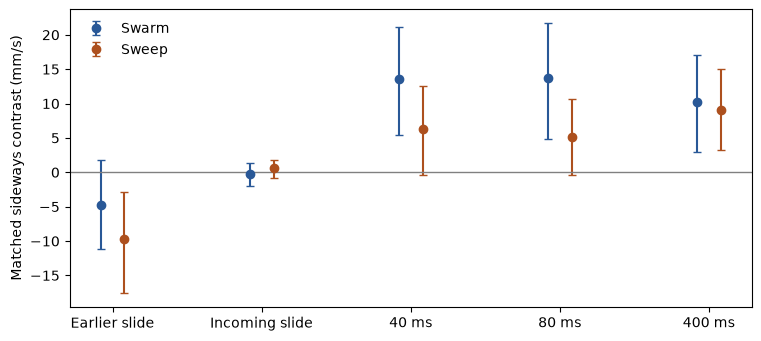

In [8]:
study = result / "direction_and_paths"
contrasts = pd.read_csv(study / "contrasts.csv")
measure_names = {"lead": "Earlier slide", "incoming": "Incoming slide",
                 "slide_400": "Measured at 400 ms", "change_400": "400 ms minus earlier slide",
                 "forecast_400": "Compact prediction"}
show = contrasts.query("scope == 'all' and measure in @measure_names").copy()
show["measure"] = show.measure.map(measure_names)
display(show[["design", "family", "measure", "pairs", "positive_records", "records",
              "mean_mm_s", "low", "high"]].round(2).set_index(["design", "family", "measure"]))
measures = ["lead", "incoming", "slide_40", "slide_80", "slide_400"]
labels = ["Earlier slide", "Incoming slide", "40 ms", "80 ms", "400 ms"]
fig, ax = plt.subplots(figsize=(7.5, 3.3), layout="constrained")
for fam, offset, color in [("swarm", -.08, "#295897"), ("sweep", .08, "#ad501e")]:
    g = contrasts.query("design == 'primary' and scope == 'all' and family == @fam").set_index("measure").loc[measures]
    ax.errorbar(np.arange(5) + offset, g.mean_mm_s, yerr=[g.mean_mm_s-g.low, g.high-g.mean_mm_s],
                fmt="o", capsize=3, color=color, label=fam.capitalize())
ax.axhline(0, lw=1, color="0.5")
ax.set_xticks(np.arange(5), labels)
ax.set_ylabel("Matched sideways contrast (mm/s)")
ax.legend(frameon=False)
plt.show()


## What happens during the next 400 ms?

For each gate we followed all native frames until 400 ms. A pair **clears** on first reaching $r_{ij}\ge1.30$, and **reapproaches** if it subsequently crosses below $1.10$. Early clearance occurs by 80 ms. A pair that stays near has a large turn if its center-to-center axis swings at least $10^\circ$ from the gate axis. These classes describe center trajectories. Physical rim contact needs an independent observation. Reapproaches and early clearances are rare at this threshold. The table also shows how the counts change at other thresholds.

A gate-only multinomial fit estimates $p_k=P(K=k\mid X_t)$, where $K$ is the path and $X_t$ contains pair distance, signed and absolute motion, spin, time previously near, crowding, third-neighbor geometry, wall clearance and PWM. Each class has a ridge normal-speed fit $m_k(X_t)$ shrunk toward the common ridge fit. The mixture forecast is $\widehat u_n=\sum_k p_k m_k(X_t)$. The retrospective column evaluates $m_K(X_t)$ with the measured future path. It shares information with the target and quantifies how informative the realized geometry is. Compare the mixture to the gate-only common fit and the archived history baseline. Metrics are averaged equally across held-out recordings. Lower Brier scores mean more accurate path probabilities.

In [9]:
counts = pd.read_csv(study / "path_counts.csv")
display(counts.pivot_table(index="rule", columns="class", values="events", aggfunc="sum", fill_value=0))
paths = pd.read_csv(study / "path_scores.csv").query("path == 'all'")
display(paths.groupby(["design", "family"])[["history_rmse", "gate_linear_rmse", "gate_mixture_rmse",
        "known_path_rmse", "gate_mixture_r2", "brier", "prior_brier"]].mean().round(3))
display(Markdown("RMSE is in mm/s. The complete [per-recording and per-path scores](results/shared_interaction/direction_and_paths/path_scores.csv) include all five forecasting and diagnostic models."))

class,early clearance,later clearance,"near, large turn","near, small turn",reapproach
rule,,,,,
path,2,5454,16567,24428,16
path_1.20_10,108,12414,13043,20478,424
path_1.30_15,2,5454,7928,33067,16
path_1.30_5,2,5454,30787,10208,16
path_1.40_10,0,2268,18261,25938,0


history_rmse  gate_linear_rmse  gate_mixture_rmse  \
design       family                                                      
cross-family swarm         13.287            12.567             12.332   
             sweep         14.639            14.348             14.468   
recording    swarm         12.667            12.088             11.977   
             sweep         14.657            14.316             14.310   

                     known_path_rmse  gate_mixture_r2  brier  prior_brier  
design       family                                                        
cross-family swarm             8.968            0.042  0.536        0.557  
             sweep             9.792            0.024  0.610        0.611  
recording    swarm             8.797            0.098  0.527        0.552  
             sweep             9.809            0.043  0.566        0.607

RMSE is in mm/s. The complete [per-recording and per-path scores](results/shared_interaction/direction_and_paths/path_scores.csv) include all five forecasting and diagnostic models.

## How should neighbors be weighted by distance?

We ran a joint EPDE search on signed tangential motion. For a radial weight function $q$, replace the triangle $(1.30-r)_+$ in $A_t$ by $q(r)$, and denote that signed sum by $B[q]$. We examined all 16 subsets of four distance terms in

$$
\widehat u_t(h)=s+a_h z s+\sum_{\ell=0}^3 b_{\ell,h}B[H_\ell],
\qquad z=\mathrm{clip}((1.30-r_{ij})/0.30,0,1).
$$

Here $s$ is incoming signed slide. Each $H_\ell(r)$ is a piecewise-linear basis function with value one at its own knot and zero at the other knots among $0.95,1.05,1.15,1.30,1.50$ body diameters. Below 0.95 the first basis stays at one. At and beyond 1.50 all four vanish. The coefficient $a_h$ is dimensionless and $b_{\ell,h}$ is in $D/\mathrm s$. The compact reference uses $s-k_hzs+d_h A_t$, with coefficients estimated in the same training fold.

Within each training prefix, EPDE screened 128 chronologically distributed gates per recording using relative absolute error on $u_t-s$ and dyadic coefficient instability. Each full-rank nondominated support was eligible. Coefficients were refit on all training-prefix gates with equal recording weights, and validation-tail RMSE selected the support. The held-out test results below compare the chosen support, the original triangular weighting, and a model omitting the third-neighbor term. The [full front and error table](results/shared_interaction/direction_and_paths/distance_fronts.csv) includes both objectives, selection flags, fitted coefficient vectors, test RMSE and test $R^2$ for all 480 fold, horizon and support combinations.

In [10]:
distance = pd.read_csv(study / "distance_scores.csv")
display(distance.groupby(["design", "family", "horizon"])[["no_third_rmse", "triangle_rmse",
        "learned_rmse", "triangle_r2", "learned_r2"]].mean().round(3))
front = pd.read_csv(study / "distance_fronts.csv")
for row in front.query("design == 'cross-family' and chosen").itertuples():
    a, *weights = json.loads(row.refit_beta)
    terms = "".join(f"{b:+.3f} B[H_{k}]" for k,b in enumerate(weights) if b != 0)
    display(Markdown(f"{row.fold.replace('train_', 'Trained on ')}, {row.horizon} ms. "
                     + rf"$\widehat u_t=s{a:+.3f}zs{terms}$."))

no_third_rmse  triangle_rmse  learned_rmse  \
design       family horizon                                               
cross-family swarm  40              36.537         35.696        34.588   
                    80              33.625         32.352        31.237   
                    400             25.030         23.057        23.250   
             sweep  40              30.129         29.240        29.312   
                    80              29.001         27.813        27.492   
                    400             29.786         27.935        27.787   
recording    swarm  40              36.016         35.352        34.351   
                    80              32.965         31.922        30.816   
                    400             24.863         23.008        23.009   
             sweep  40              29.746         28.939        28.628   
                    80              28.525         27.448        27.092   
                    400             29.670         27.849        27.555   

                             triangle_r2  learned_r2  
design       family horizon                           
cross-family swarm  40             0.209       0.257  
                    80             0.205       0.258  
                    400            0.151       0.135  
             sweep  40             0.435       0.433  
                    80             0.432       0.445  
                    400            0.236       0.244  
recording    swarm  40             0.225       0.267  
                    80             0.227       0.279  
                    400            0.157       0.156  
             sweep  40             0.447       0.459  
                    80             0.446       0.461  
                    400            0.240       0.256

Trained on swarm, 40 ms. $\widehat u_t=s-0.609zs+0.833 B[H_0]-0.051 B[H_3]$.

Trained on swarm, 80 ms. $\widehat u_t=s-0.649zs+0.711 B[H_0]+0.173 B[H_1]-0.044 B[H_2]-0.004 B[H_3]$.

Trained on swarm, 400 ms. $\widehat u_t=s-0.972zs+0.479 B[H_0]+0.257 B[H_1]+0.136 B[H_2]+0.040 B[H_3]$.

Trained on sweep, 40 ms. $\widehat u_t=s-0.367zs+0.785 B[H_0]+0.184 B[H_1]$.

Trained on sweep, 80 ms. $\widehat u_t=s-0.412zs+0.842 B[H_0]+0.251 B[H_1]+0.068 B[H_2]+0.073 B[H_3]$.

Trained on sweep, 400 ms. $\widehat u_t=s-0.846zs+0.548 B[H_0]+0.354 B[H_1]+0.232 B[H_2]+0.158 B[H_3]$.

## Does the direction survive a longer motion-history check?

We compared opposite signs of $A_t$ among gates with complete observations of earlier motion. The same seven original calipers, spin-sign strata and distinct neighbor count apply in all four designs. Each matched pair is more than 1.28 seconds apart, so the 880 ms prehistory and 400 ms outcome windows of its two members are disjoint. “Common history” is the comparison on this eligible sample. Two designs additionally require the signed sideways velocities measured 640–440 ms before the gate to agree within either $0.40D/\mathrm{s}$ or $0.25D/\mathrm{s}$. The 880 to 680 ms interval is held out in those comparisons. After seeing residual imbalance in that interval in the sweeps, we also ran an exploratory fourth design requiring both earlier velocities to agree within $0.25D/\mathrm{s}$. All velocities are projected onto the eventual gate tangent.

The table reports the positive-minus-negative $A_t$ contrast. Each recording has equal weight within its family. Pointwise 95% intervals use 4,000 resamples of occupied 30-second blocks within recording with the matches held fixed. The intervals describe the available recordings. Positive means that the high-$A_t$ group had greater signed sideways velocity on average. A single match can involve several nearby robots.

With both earlier intervals matched, seven swarm comparisons and five sweep comparisons survived. Every surviving gate involved multiple third neighbors. Only three of five swarm recordings contributed; two of three sweep recordings contributed a single comparison apiece. The latter comparisons add no within-recording variability in the conditional block intervals. The observed 400 ms differences were +7.7 mm/s for swarms and +2.7 mm/s for sweeps, with both intervals crossing zero.

In [11]:
motion = pd.read_csv(study / "motion_match_families.csv")
stage_names = {"earlier_t": "880 to 680 ms before", "lead_t": "640 to 440 ms before",
               "side": "120 to 40 ms before", "y80_t": "80 ms after", "y400_t": "400 ms after"}
history_summary = motion[motion.measure.isin(stage_names)].copy()
history_summary["window"] = history_summary.measure.map(stage_names)
display(history_summary.set_index(["design", "family", "window"])[
    ["pairs", "recordings", "positive_records", "mean_mm_s", "low", "high"]].round(2))

pairs  recordings  \
design         family window                                    
common history swarm  880 to 680 ms before     83           5   
                      640 to 440 ms before     83           5   
                      120 to 40 ms before      83           5   
                      80 ms after              83           5   
                      400 ms after             83           5   
               sweep  880 to 680 ms before     86           3   
                      640 to 440 ms before     86           3   
                      120 to 40 ms before      86           3   
                      80 ms after              86           3   
                      400 ms after             86           3   
lead 0.40      swarm  880 to 680 ms before     40           5   
                      640 to 440 ms before     40           5   
                      120 to 40 ms before      40           5   
                      80 ms after              40           5   
                      400 ms after             40           5   
               sweep  880 to 680 ms before     39           3   
                      640 to 440 ms before     39           3   
                      120 to 40 ms before      39           3   
                      80 ms after              39           3   
                      400 ms after             39           3   
lead 0.25      swarm  880 to 680 ms before     29           5   
                      640 to 440 ms before     29           5   
                      120 to 40 ms before      29           5   
                      80 ms after              29           5   
                      400 ms after             29           5   
               sweep  880 to 680 ms before     28           3   
                      640 to 440 ms before     28           3   
                      120 to 40 ms before      28           3   
                      80 ms after              28           3   
                      400 ms after             28           3   
both 0.25      swarm  880 to 680 ms before      7           3   
                      640 to 440 ms before      7           3   
                      120 to 40 ms before       7           3   
                      80 ms after               7           3   
                      400 ms after              7           3   
               sweep  880 to 680 ms before      5           3   
                      640 to 440 ms before      5           3   
                      120 to 40 ms before       5           3   
                      80 ms after               5           3   
                      400 ms after              5           3   

                                            positive_records  mean_mm_s  \
design         family window                                              
common history swarm  880 to 680 ms before                 3      -3.59   
                      640 to 440 ms before                 0      -4.91   
                      120 to 40 ms before                  1      -0.39   
                      80 ms after                          5      13.47   
                      400 ms after                         5      10.59   
               sweep  880 to 680 ms before                 0     -10.58   
                      640 to 440 ms before                 0     -13.26   
                      120 to 40 ms before                  2       0.61   
                      80 ms after                          2       4.60   
                      400 ms after                         3       8.05   
lead 0.40      swarm  880 to 680 ms before                 3      -0.63   
                      640 to 440 ms before                 2       0.53   
                      120 to 40 ms before                  1      -2.00   
                      80 ms after                          4      20.44   
                      400 ms after                         5       7.85   
               sweep  880 to 680 ms be

## How consistently does distance weighting improve the 80 ms sideways forecast?

For the same held-out gates, define the gain as $\mathrm{RMSE}_{\mathrm{triangle}}-\mathrm{RMSE}_{\mathrm{radial}}$ in mm/s. We replayed the archived EPDE coefficients and computed paired intervals using the same 30-second block draws for both forecasts. The comparison uses the compact triangular equation fitted on the same training prefixes. “No apparent overlap” requires that the focal pair and every focal-to-third center distance are at least $1.00D$ at the gate and that every third neighbor within $1.50D$ has an unflagged position. The apparent-overlap subset passes the same quality check and has at least one of those distances below $1.00D$. Flagged-neighbor gates enter the all-gates results. This sensitivity check uses gate geometry only. Calibration uncertainty remains, and tracked centers alone cannot establish physical rim contact.

The first table follows the previously reported 80 ms forecasts in both held-out designs. Cross-family prediction trains on the other recording family. Each family mean gives equal weight to its recordings. The figure compares the full and overlap-screened cross-family samples for each recording. Error bars condition on the fitted coefficients, the available recordings, and the gate selection.

The mean cross-family RMSE gain on the overlap-screened gates was 1.02 mm/s in swarms and 0.32 mm/s in sweeps. All eight recording-level gains had positive conditional lower bounds. The largest gains on all gates occurred in the two PWM 20 swarm recordings. Acquisition settings and physical robots differed across recordings, so the comparison measures predictive transfer.

events  positive_records  recordings  \
design       family cohort                                                      
cross-family sweep  all                   24261                 3           3   
                    no apparent overlap   24117                 3           3   
                    apparent overlap        144                 2           3   
             swarm  all                   22206                 5           5   
                    no apparent overlap   19643                 5           5   
                    apparent overlap       2018                 3           5   
recording    sweep  all                   24261                 3           3   
                    no apparent overlap   24117                 3           3   
                    apparent overlap        144                 2           3   
             swarm  all                   22206                 5           5   
                    no apparent overlap   19643                 5           5   
                    apparent overlap       2018                 3           5   

                                           rmse  triangle_rmse   gain    low  \
design       family cohort                                                     
cross-family sweep  all                  27.492         27.813  0.321  0.241   
                    no apparent overlap  27.479         27.797  0.318  0.236   
                    apparent overlap     29.116         29.650  0.535 -2.866   
             swarm  all                  31.237         32.352  1.115  1.020   
                    no apparent overlap  31.151         32.167  1.016  0.924   
                    apparent overlap     32.546         33.998  1.452  0.646   
recording    sweep  all                  27.092         27.448  0.356  0.286   
                    no apparent overlap  27.077         27.431  0.353  0.283   
                    apparent overlap     29.082         29.536  0.454 -3.107   
             swarm  all                  30.816         31.922  1.106  1.000   
                    no apparent overlap  30.751         31.788  1.037  0.935   
                    apparent overlap     31.837         32.937  1.100  0.301   

                                          high     r2  
design       family cohort                             
cross-family sweep  all                  0.401  0.445  
                    no apparent overlap  0.398  0.445  
                    apparent overlap     3.078  0.309  
             swarm  all                  1.209  0.258  
                    no apparent overlap  1.113  0.263  
                    apparent overlap     2.169  0.142  
recording    sweep  all                  0.424  0.461  
                    no apparent overlap  0.420  0.461  
                    apparent overlap     3.107  0.311  
             swarm  all                  1.209  0.279  
                    no apparent overlap  1.137  0.283  
                    apparent overlap     1.877  0.178

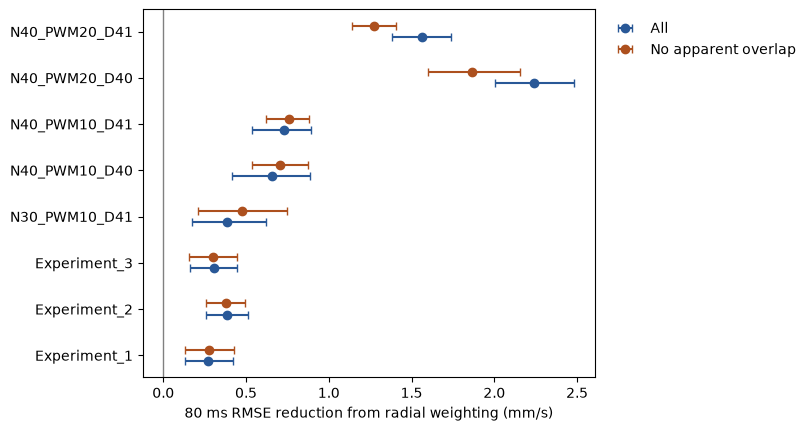

In [12]:
gain = pd.read_csv(study / "kernel80_families.csv", dtype={"mask": str})
cols = ["events", "positive_records", "recordings", "rmse", "triangle_rmse", "gain", "low", "high", "r2"]
display(gain.query("mask == 'archived'").set_index(["design", "family", "cohort"])[cols].round(3))
kernel_records = pd.read_csv(study / "kernel80_recordings.csv")
transferred = kernel_records.query("design == 'cross-family' and previous")
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
recordings = sorted(transferred.recording.unique())
for cohort, shift, color in [("all", -.12, "#295897"), ("no apparent overlap", .12, "#ad501e")]:
    rows = transferred[transferred.cohort == cohort].set_index("recording").loc[recordings]
    ax.errorbar(rows.gain, np.arange(len(rows)) + shift,
                xerr=[rows.gain - rows.low, rows.high - rows.gain], fmt="o",
                capsize=3, color=color, label=cohort.capitalize())
ax.axvline(0, lw=1, color="0.5")
ax.set_yticks(np.arange(len(recordings)), recordings)
ax.set_xlabel("80 ms RMSE reduction from radial weighting (mm/s)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.savefig(study / "kernel80_recording_gains.pdf", bbox_inches="tight")
plt.show()

### Complete 80 ms nondominated fronts

The two search objectives are training WAPE on $u_t-s$ and dyadic coefficient instability. Smaller values are preferred on both. The table displays every nondominated structure in every search fold, in mask order within fold for lookup. $B[H_\ell]$ is the signed tangential projection of the distance-weighted neighbor sum defined above. The displayed coefficients are the full-prefix refits. Test errors, $R^2$, and intervals describe held-out motion. The archive includes the test results for [all 16 supports in every fold](results/shared_interaction/direction_and_paths/distance_fronts.csv) and [paired error intervals by recording](results/shared_interaction/direction_and_paths/kernel80_recordings.csv).

Across the ten training folds, there are 44 nondominated entries. Two structures occurred on every front: $s+a zs$ and $s+a zs+b_0 B[H_0]+b_1 B[H_1]$. The latter gives nonzero neighbor weight only inside $1.15D$ and describes a compact shared shape. The full table retains the other trade-offs and the fitted coefficients for each fold.

In [13]:
fold_front = front.query("horizon == 80 and on_front").sort_values(["design", "fold", "mask"])
rows = ["| Training or held-out fold | Mask | Equation | WAPE | Instability | Test RMSE (mm/s) | Test $R^2$ |",
        "|---|---:|---|---:|---:|---:|---:|"]
for entry in fold_front.itertuples():
    a, *weights = json.loads(entry.refit_beta)
    terms = "".join(f"{b:+.4f} B[H_{k}]" for k,b in enumerate(weights) if b != 0)
    equation = rf"$\widehat u_t=s{a:+.4f}zs{terms}$"
    rows.append(f"| {entry.fold} | {entry.mask} | {equation} | {entry.wape:.3f} | {entry.dyad:.3f} "
                f"| {entry.test_rmse_mm_s:.3f} | {entry.test_r2:.3f} |")
display(Markdown("\n".join(rows)))

| Training or held-out fold | Mask | Equation | WAPE | Instability | Test RMSE (mm/s) | Test $R^2$ |
|---|---:|---|---:|---:|---:|---:|
| train_swarm | 1 | $\widehat u_t=s-0.7749zs$ | 0.878 | 0.215 | 29.001 | 0.382 |
| train_swarm | 3 | $\widehat u_t=s-0.6981zs+0.8663 B[H_0]$ | 0.846 | 0.549 | 28.075 | 0.421 |
| train_swarm | 7 | $\widehat u_t=s-0.6455zs+0.7475 B[H_0]+0.1881 B[H_1]$ | 0.836 | 1.526 | 27.375 | 0.449 |
| train_swarm | 11 | $\widehat u_t=s-0.6968zs+0.7731 B[H_0]-0.0954 B[H_2]$ | 0.841 | 1.174 | 28.329 | 0.410 |
| train_swarm | 15 | $\widehat u_t=s-0.6483zs+0.7135 B[H_0]+0.1759 B[H_1]-0.0428 B[H_2]$ | 0.833 | 2.378 | 27.479 | 0.445 |
| train_swarm | 31 | $\widehat u_t=s-0.6485zs+0.7112 B[H_0]+0.1733 B[H_1]-0.0443 B[H_2]-0.0043 B[H_3]$ | 0.833 | 5.766 | 27.492 | 0.445 |
| train_sweep | 1 | $\widehat u_t=s-0.4710zs$ | 0.912 | 0.308 | 33.625 | 0.143 |
| train_sweep | 5 | $\widehat u_t=s-0.4254zs+0.2632 B[H_1]$ | 0.859 | 0.620 | 32.382 | 0.205 |
| train_sweep | 7 | $\widehat u_t=s-0.4187zs+0.7562 B[H_0]+0.2172 B[H_1]$ | 0.846 | 1.740 | 31.062 | 0.267 |
| train_sweep | 15 | $\widehat u_t=s-0.4164zs+0.8217 B[H_0]+0.2173 B[H_1]+0.0563 B[H_2]$ | 0.843 | 1.980 | 31.195 | 0.260 |
| train_sweep | 31 | $\widehat u_t=s-0.4122zs+0.8418 B[H_0]+0.2508 B[H_1]+0.0676 B[H_2]+0.0728 B[H_3]$ | 0.843 | 8.974 | 31.237 | 0.258 |
| Experiment_1 | 1 | $\widehat u_t=s-0.6985zs$ | 0.889 | 0.253 | 28.489 | 0.400 |
| Experiment_1 | 3 | $\widehat u_t=s-0.6335zs+0.9084 B[H_0]$ | 0.855 | 0.547 | 27.847 | 0.427 |
| Experiment_1 | 7 | $\widehat u_t=s-0.5854zs+0.7652 B[H_0]+0.1978 B[H_1]$ | 0.838 | 1.378 | 27.220 | 0.453 |
| Experiment_1 | 11 | $\widehat u_t=s-0.6333zs+0.8456 B[H_0]-0.0631 B[H_2]$ | 0.855 | 1.317 | 28.011 | 0.420 |
| Experiment_1 | 15 | $\widehat u_t=s-0.5863zs+0.7509 B[H_0]+0.1937 B[H_1]-0.0173 B[H_2]$ | 0.838 | 2.357 | 27.255 | 0.451 |
| Experiment_2 | 1 | $\widehat u_t=s-0.6933zs$ | 0.893 | 0.217 | 28.640 | 0.389 |
| Experiment_2 | 3 | $\widehat u_t=s-0.6287zs+0.9047 B[H_0]$ | 0.863 | 0.567 | 27.884 | 0.421 |
| Experiment_2 | 7 | $\widehat u_t=s-0.5815zs+0.7633 B[H_0]+0.1964 B[H_1]$ | 0.843 | 1.705 | 27.211 | 0.449 |
| Experiment_2 | 23 | $\widehat u_t=s-0.5809zs+0.7694 B[H_0]+0.2085 B[H_1]+0.0251 B[H_3]$ | 0.843 | 3.420 | 27.166 | 0.451 |
| Experiment_3 | 1 | $\widehat u_t=s-0.7021zs$ | 0.885 | 0.254 | 28.446 | 0.417 |
| Experiment_3 | 3 | $\widehat u_t=s-0.6382zs+0.9080 B[H_0]$ | 0.857 | 0.618 | 27.499 | 0.455 |
| Experiment_3 | 7 | $\widehat u_t=s-0.5894zs+0.7674 B[H_0]+0.1978 B[H_1]$ | 0.841 | 1.677 | 26.854 | 0.481 |
| N30_PWM10_D41 | 1 | $\widehat u_t=s-0.6985zs$ | 0.882 | 0.247 | 28.217 | 0.366 |
| N30_PWM10_D41 | 3 | $\widehat u_t=s-0.6351zs+0.9565 B[H_0]$ | 0.853 | 0.591 | 27.172 | 0.412 |
| N30_PWM10_D41 | 7 | $\widehat u_t=s-0.5842zs+0.8043 B[H_0]+0.2065 B[H_1]$ | 0.834 | 1.689 | 26.836 | 0.426 |
| N40_PWM10_D40 | 1 | $\widehat u_t=s-0.6609zs$ | 0.893 | 0.264 | 27.912 | 0.152 |
| N40_PWM10_D40 | 3 | $\widehat u_t=s-0.5988zs+0.9709 B[H_0]$ | 0.863 | 0.577 | 27.369 | 0.185 |
| N40_PWM10_D40 | 7 | $\widehat u_t=s-0.5550zs+0.8105 B[H_0]+0.2029 B[H_1]$ | 0.844 | 1.696 | 26.595 | 0.230 |
| N40_PWM10_D41 | 1 | $\widehat u_t=s-0.6774zs$ | 0.894 | 0.232 | 27.173 | 0.291 |
| N40_PWM10_D41 | 3 | $\widehat u_t=s-0.6165zs+0.9470 B[H_0]$ | 0.861 | 0.579 | 26.183 | 0.342 |
| N40_PWM10_D41 | 5 | $\widehat u_t=s-0.6012zs+0.2770 B[H_1]$ | 0.858 | 0.647 | 27.070 | 0.297 |
| N40_PWM10_D41 | 7 | $\widehat u_t=s-0.5668zs+0.7824 B[H_0]+0.2192 B[H_1]$ | 0.834 | 1.344 | 26.233 | 0.339 |
| N40_PWM10_D41 | 15 | $\widehat u_t=s-0.5669zs+0.7809 B[H_0]+0.2189 B[H_1]-0.0018 B[H_2]$ | 0.834 | 2.024 | 26.229 | 0.340 |
| N40_PWM20_D40 | 1 | $\widehat u_t=s-0.6078zs$ | 0.897 | 0.257 | 42.201 | -0.020 |
| N40_PWM20_D40 | 3 | $\widehat u_t=s-0.5609zs+0.8679 B[H_0]$ | 0.870 | 0.614 | 39.162 | 0.122 |
| N40_PWM20_D40 | 5 | $\widehat u_t=s-0.5453zs+0.2406 B[H_1]$ | 0.866 | 0.644 | 40.625 | 0.055 |
| N40_PWM20_D40 | 7 | $\widehat u_t=s-0.5200zs+0.7027 B[H_0]+0.1921 B[H_1]$ | 0.848 | 1.665 | 38.313 | 0.159 |
| N40_PWM20_D40 | 15 | $\widehat u_t=s-0.5198zs+0.7047 B[H_0]+0.1925 B[H_1]+0.0025 B[H_2]$ | 0.847 | 2.167 | 38.320 | 0.159 |
| N40_PWM20_D40 | 31 | $\widehat u_t=s-0.5176zs+0.7218 B[H_0]+0.2127 B[H_1]+0.0126 B[H_2]+0.0380 B[H_3]$ | 0.847 | 5.702 | 38.380 | 0.157 |
| N40_PWM20_D41 | 1 | $\widehat u_t=s-0.6339zs$ | 0.904 | 0.272 | 39.319 | 0.097 |
| N40_PWM20_D41 | 3 | $\widehat u_t=s-0.5808zs+0.8966 B[H_0]$ | 0.873 | 0.595 | 37.097 | 0.196 |
| N40_PWM20_D41 | 7 | $\widehat u_t=s-0.5399zs+0.7497 B[H_0]+0.1877 B[H_1]$ | 0.852 | 1.692 | 36.005 | 0.243 |
| N40_PWM20_D41 | 23 | $\widehat u_t=s-0.5384zs+0.7585 B[H_0]+0.2055 B[H_1]+0.0375 B[H_3]$ | 0.851 | 3.984 | 36.043 | 0.241 |

### Controlled replication

The primary matched association at 400 ms is positive in all eight recordings. The tighter design has 24 swarm pairs and 19 sweep pairs, with both intervals crossing zero. The earlier sideways contrast in sweeps also suggests that the third-neighbor geometry selects pairs with different motion histories. Changing the radial weighting gives small, horizon-dependent gains, and the held-out normal-speed mixture still has low $R^2$.

The [randomized 96-trial sheet](collision/prospective/mirror_trials.csv) tests whether placing the same third robot on opposite sides of focal robot $j$ changes $u_t(0.4)$. Holding the incoming motion fixed, the frozen compact equation predicts a **20.9 mm/s** mirror contrast for the ideal placements, with the absent arm at their midpoint. Record departures from the target geometry and score each first assigned gate. The [protocol and trial analyzer](collision/prospective/PROTOCOL.md#mirrored-third-robot-placement) specify scoring and missing trials. This pilot awaits acquisition.

## Reproduction

From the repository root run the data extraction, optical audit, primary fit, fixed-persistence fit, report and verification in that order. The optical audit accepts the video directories and FFmpeg executable as command arguments. The fit uses the joint EPDE least-squares and dyadic-instability implementations. The verification replays forecasts and checks robot exchange, reflection and rotation. Units in the saved prediction arrays are diameters/s. Public RMSE, MAE and gains are in mm/s.

[Data extraction](collision/shared_interaction_data.py) · [Video measurements](collision/shared_interaction_optics.py) · [Search and model selection](collision/shared_interaction_fit.py) · [Scoring](collision/shared_interaction_report.py) · [Verification](collision/shared_interaction_verify.py)

~~~powershell
python projects/robot/collision/shared_interaction_data.py
python projects/robot/collision/shared_interaction_optics.py
python projects/robot/collision/shared_interaction_fit.py
python projects/robot/collision/shared_interaction_fit.py --fixed-drive
python projects/robot/collision/shared_interaction_report.py
python projects/robot/collision/shared_interaction_verify.py
python projects/robot/collision/shared_interaction_compact.py --replay
python projects/robot/collision/interaction_paths.py
python projects/robot/collision/third_neighbor_study.py
python projects/robot/collision/neighbor_robustness.py
~~~